In [ ]:
# Spatiotemporal Congestion and Anomaly Detection via Multi-Vehicle Deep Learning

This notebook supports the 6CS030 Big Data coursework project. The project uses the UK Department for Transport traffic count dataset to analyse traffic patterns by time, location, road type, and vehicle category.

Apache Hadoop HDFS is used to store the large raw dataset, while Apache Spark is used for scalable data loading, cleaning, preprocessing, and exploratory analysis. After preprocessing, machine learning and deep learning models are developed to predict traffic flow and support congestion/anomaly detection.
    

In [9]:
import sys
print(sys.executable)

/usr/bin/python3


In [10]:
import sys
!{sys.executable} -m pip install pyspark

Defaulting to user installation because normal site-packages is not writeable


In [1]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("Spatiotemporal_Congestion_Anomaly_Detection") \
    .config("spark.sql.shuffle.partitions", "8") \
    .getOrCreate()

print("Spark session created successfully")
print("Spark version:", spark.version)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/05/14 16:04:49 WARN Utils: Your hostname, LAPTOP-N51U7423, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/05/14 16:04:49 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/05/14 16:04:50 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark session created successfully
Spark version: 4.1.1


In [12]:
traffic_df = spark.read.csv(
    "hdfs:///traffic_data/dft_traffic_counts_raw_counts.csv",
    header=True,
    inferSchema=True
)

print("Rows:", traffic_df.count())
print("Columns:", len(traffic_df.columns))

traffic_df.printSchema()
traffic_df.show(5, truncate=False)

Rows: 5113740
Columns: 35
root
 |-- count_point_id: integer (nullable = true)
 |-- direction_of_travel: string (nullable = true)
 |-- year: integer (nullable = true)
 |-- count_date: date (nullable = true)
 |-- hour: integer (nullable = true)
 |-- region_id: integer (nullable = true)
 |-- region_name: string (nullable = true)
 |-- region_ons_code: string (nullable = true)
 |-- local_authority_id: integer (nullable = true)
 |-- local_authority_name: string (nullable = true)
 |-- local_authority_code: string (nullable = true)
 |-- road_name: string (nullable = true)
 |-- road_category: string (nullable = true)
 |-- road_type: string (nullable = true)
 |-- start_junction_road_name: string (nullable = true)
 |-- end_junction_road_name: string (nullable = true)
 |-- easting: integer (nullable = true)
 |-- northing: integer (nullable = true)
 |-- latitude: double (nullable = true)
 |-- longitude: double (nullable = true)
 |-- link_length_km: string (nullable = true)
 |-- link_length_miles: s

In [13]:
from pyspark.sql.functions import expr

numeric_columns = [
    "link_length_km",
    "link_length_miles",
    "pedal_cycles",
    "two_wheeled_motor_vehicles",
    "cars_and_taxis",
    "buses_and_coaches",
    "LGVs",
    "HGVs_2_rigid_axle",
    "HGVs_3_rigid_axle",
    "HGVs_4_or_more_rigid_axle",
    "HGVs_3_or_4_articulated_axle",
    "HGVs_5_articulated_axle",
    "HGVs_6_articulated_axle",
    "all_HGVs",
    "all_motor_vehicles"
]

traffic_clean = traffic_df

for column_name in numeric_columns:
    traffic_clean = traffic_clean.withColumn(
        column_name,
        expr(f"try_cast({column_name} as double)")
    )

print("Numeric columns converted safely using try_cast.")
traffic_clean.printSchema()

Numeric columns converted safely using try_cast.
root
 |-- count_point_id: integer (nullable = true)
 |-- direction_of_travel: string (nullable = true)
 |-- year: integer (nullable = true)
 |-- count_date: date (nullable = true)
 |-- hour: integer (nullable = true)
 |-- region_id: integer (nullable = true)
 |-- region_name: string (nullable = true)
 |-- region_ons_code: string (nullable = true)
 |-- local_authority_id: integer (nullable = true)
 |-- local_authority_name: string (nullable = true)
 |-- local_authority_code: string (nullable = true)
 |-- road_name: string (nullable = true)
 |-- road_category: string (nullable = true)
 |-- road_type: string (nullable = true)
 |-- start_junction_road_name: string (nullable = true)
 |-- end_junction_road_name: string (nullable = true)
 |-- easting: integer (nullable = true)
 |-- northing: integer (nullable = true)
 |-- latitude: double (nullable = true)
 |-- longitude: double (nullable = true)
 |-- link_length_km: double (nullable = true)
 |

## Missing value check

In [26]:
from pyspark.sql.functions import col, sum as spark_sum, when

In [27]:
missing_values = traffic_clean.select([
    spark_sum(when(col(c).isNull(), 1).otherwise(0)).alias(c)
    for c in traffic_clean.columns
])

missing_values.show(vertical=True)

[Stage 39:>                                                         (0 + 8) / 8]

-RECORD 0-------------------------------
 count_point_id               | 0       
 direction_of_travel          | 0       
 year                         | 0       
 count_date                   | 0       
 hour                         | 0       
 region_id                    | 0       
 region_name                  | 0       
 region_ons_code              | 0       
 local_authority_id           | 0       
 local_authority_name         | 0       
 local_authority_code         | 0       
 road_name                    | 0       
 road_category                | 0       
 road_type                    | 0       
 start_junction_road_name     | 0       
 end_junction_road_name       | 0       
 easting                      | 0       
 northing                     | 0       
 latitude                     | 0       
 longitude                    | 0       
 link_length_km               | 2800104 
 link_length_miles            | 2800104 
 pedal_cycles                 | 0       
 two_wheeled_mot

## Cleaning the Rows

In [28]:
rows_before_cleaning = traffic_clean.count()

traffic_clean = traffic_clean.filter(
    (col("all_motor_vehicles").isNotNull()) &
    (col("all_motor_vehicles") >= 0) &
    (col("count_date").isNotNull()) &
    (col("hour").isNotNull()) &
    (col("region_name").isNotNull()) &
    (col("local_authority_name").isNotNull()) &
    (col("road_name").isNotNull()) &
    (col("latitude").isNotNull()) &
    (col("longitude").isNotNull())
)

rows_after_cleaning = traffic_clean.count()

print("Rows before cleaning:", rows_before_cleaning)
print("Rows after cleaning:", rows_after_cleaning)
print("Rows removed:", rows_before_cleaning - rows_after_cleaning)

[Stage 51:>                                                         (0 + 8) / 8]

Rows before cleaning: 5113740
Rows after cleaning: 5113725
Rows removed: 15


## Cleaning the dublicate rows

In [29]:
rows_before_duplicates = traffic_clean.count()

traffic_clean = traffic_clean.dropDuplicates()

rows_after_duplicates = traffic_clean.count()

print("Rows before duplicate removal:", rows_before_duplicates)
print("Rows after duplicate removal:", rows_after_duplicates)
print("Duplicate rows removed:", rows_before_duplicates - rows_after_duplicates)

[Stage 63:=============================>                            (4 + 4) / 8]

Rows before duplicate removal: 5113725
Rows after duplicate removal: 5113725
Duplicate rows removed: 0


## Saving the cleaned dataset back to HDFS in Parquet format

In [30]:
traffic_clean.write.mode("overwrite").parquet(
    "hdfs:///traffic_data/cleaned_traffic_counts_parquet"
)

print("Cleaned data saved to HDFS as Parquet.")

26/05/14 10:42:31 WARN MemoryManager: Total allocation exceeds 95.00% (1,020,054,720 bytes) of heap memory
Scaling row group sizes to 95.00% for 8 writers
                                                                                

Cleaned data saved to HDFS as Parquet.


In [31]:
cleaned_check = spark.read.parquet(
    "hdfs:///traffic_data/cleaned_traffic_counts_parquet"
)

print("Cleaned rows:", cleaned_check.count())
print("Cleaned columns:", len(cleaned_check.columns))


Cleaned rows: 5113725
Cleaned columns: 35


## 5. Exploratory Data Analysis and Visualisation

This section explores traffic patterns by time, location, road type, and vehicle category. Apache Spark is used to aggregate the large dataset, and the smaller aggregated results are converted to Pandas for visualisation.

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, avg, count, sum as spark_sum, month, dayofweek

import numpy as np
import matplotlib.pyplot as plt

spark = SparkSession.builder \
    .appName("Extra_Big_Data_EDA") \
    .config("spark.sql.shuffle.partitions", "4") \
    .config("spark.driver.memory", "3g") \
    .getOrCreate()

traffic_labelled = spark.read.parquet(
    "hdfs:///traffic_data/traffic_with_anomaly_label"
)

print("Labelled dataset loaded.")
print("Rows:", traffic_labelled.count())
print("Columns:", len(traffic_labelled.columns))

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/05/14 16:07:09 WARN Utils: Your hostname, LAPTOP-N51U7423, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/05/14 16:07:09 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/05/14 16:07:10 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
                                                                                

Labelled dataset loaded.


[Stage 1:=======>                                                 (2 + 14) / 16]

Rows: 5113725
Columns: 36


In [32]:
from pyspark.sql.functions import avg, sum as spark_sum, count

traffic_by_hour = traffic_clean.groupBy("hour") \
    .agg(
        avg("all_motor_vehicles").alias("avg_traffic_flow"),
        spark_sum("all_motor_vehicles").alias("total_traffic_flow"),
        count("*").alias("record_count")
    ) \
    .orderBy("hour")

traffic_by_hour.show(24)

[Stage 76:===========================================>              (6 + 2) / 8]

+----+-----------------+------------------+------------+
|hour| avg_traffic_flow|total_traffic_flow|record_count|
+----+-----------------+------------------+------------+
|   0|             39.0|              39.0|           1|
|   1|           138.25|             553.0|           4|
|   3|             28.0|              28.0|           1|
|   4|            570.0|             570.0|           1|
|   5|              5.0|               5.0|           1|
|   7|583.6098338804944|      2.48698911E8|      426139|
|   8|642.3028420037406|       2.7371286E8|      426143|
|   9|510.6948575826837|      2.17628528E8|      426142|
|  10|461.4340316888188|      1.96637344E8|      426144|
|  11|467.8826851956146|      1.99385399E8|      426144|
|  12|483.5698097356762|      2.06070373E8|      426144|
|  13|497.2339895293364|      2.11892784E8|      426143|
|  14|518.8419200037546|       2.2110189E8|      426145|
|  15|572.7809120860554|      2.44087149E8|      426144|
|  16|646.1455001126379|      2

In [33]:
import sys
!{sys.executable} -m pip install matplotlib --default-timeout=300

Defaulting to user installation because normal site-packages is not writeable


In [34]:
import matplotlib.pyplot as plt

print("Matplotlib imported successfully.")

Matplotlib imported successfully.


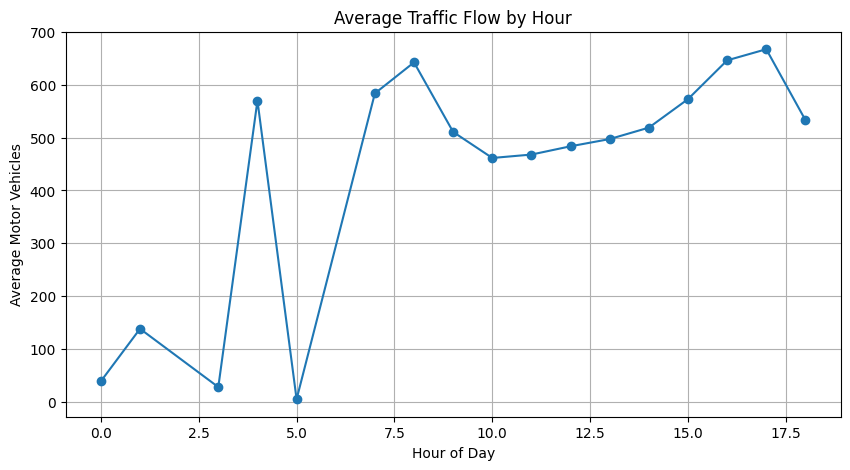

In [36]:
hour_rows = traffic_by_hour.collect()

hours = [row["hour"] for row in hour_rows]
avg_flow = [row["avg_traffic_flow"] for row in hour_rows]

plt.figure(figsize=(10, 5))
plt.plot(hours, avg_flow, marker="o")

plt.title("Average Traffic Flow by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Motor Vehicles")
plt.grid(True)
plt.show()

## Analyse traffic by region

In [37]:
traffic_by_region = traffic_clean.groupBy("region_name") \
    .agg(
        spark_sum("all_motor_vehicles").alias("total_traffic_flow"),
        avg("all_motor_vehicles").alias("avg_traffic_flow"),
        count("*").alias("record_count")
    ) \
    .orderBy(col("total_traffic_flow").desc())

traffic_by_region.show(truncate=False)

[Stage 95:>                                                         (0 + 8) / 8]

+------------------------+------------------+------------------+------------+
|region_name             |total_traffic_flow|avg_traffic_flow  |record_count|
+------------------------+------------------+------------------+------------+
|South East              |5.06903576E8      |622.3532078158859 |814495      |
|North West              |3.85184646E8      |643.380195727665  |598689      |
|London                  |3.05906246E8      |738.4562644387098 |414251      |
|East of England         |2.99468371E8      |527.5953048748261 |567610      |
|West Midlands           |2.68119385E8      |540.0450072108218 |496476      |
|Yorkshire and the Humber|2.41488154E8      |547.3687701165057 |441180      |
|South West              |2.16561976E8      |424.53143574061005|510120      |
|East Midlands           |2.13514218E8      |516.589569698656  |413315      |
|North East              |1.29786278E8      |540.2404199169157 |240238      |
|Wales                   |1.24510389E8      |411.18728761224145|

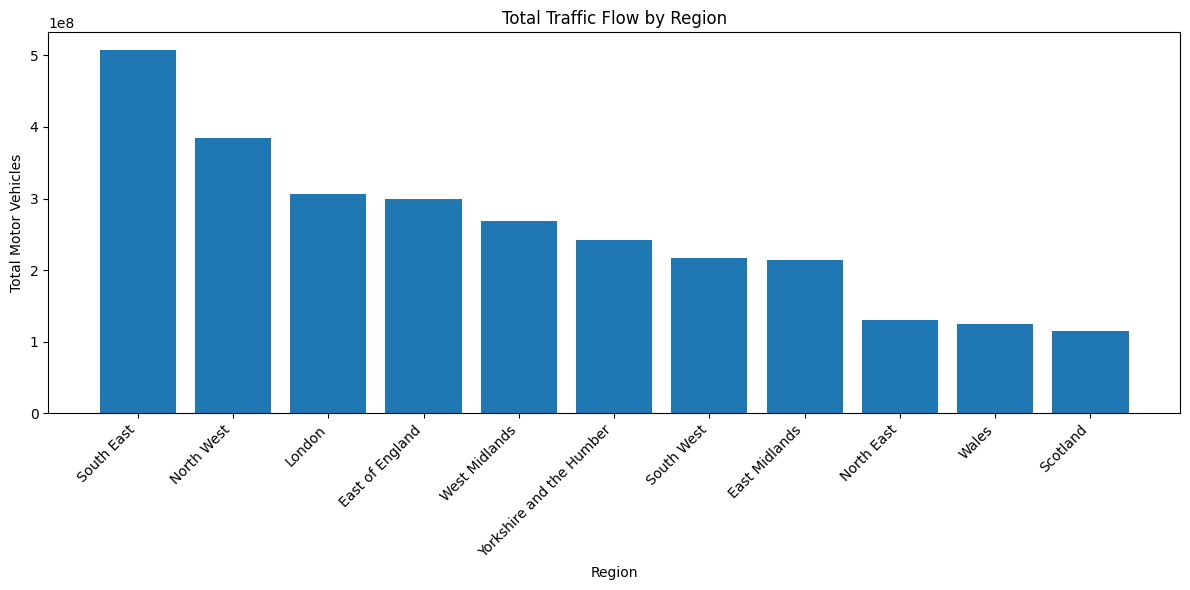

In [38]:
region_rows = traffic_by_region.collect()

regions = [row["region_name"] for row in region_rows]
total_flow = [row["total_traffic_flow"] for row in region_rows]

plt.figure(figsize=(12, 6))
plt.bar(regions, total_flow)

plt.title("Total Traffic Flow by Region")
plt.xlabel("Region")
plt.ylabel("Total Motor Vehicles")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Analyse traffic by road type

In [39]:
traffic_by_road_type = traffic_clean.groupBy("road_type") \
    .agg(
        spark_sum("all_motor_vehicles").alias("total_traffic_flow"),
        avg("all_motor_vehicles").alias("avg_traffic_flow"),
        count("*").alias("record_count")
    ) \
    .orderBy(col("total_traffic_flow").desc())

traffic_by_road_type.show(truncate=False)

[Stage 114:>                                                        (0 + 8) / 8]

+---------+------------------+------------------+------------+
|road_type|total_traffic_flow|avg_traffic_flow  |record_count|
+---------+------------------+------------------+------------+
|Major    |2.449620676E9     |1058.7775993665368|2313631     |
|Minor    |3.56445437E8      |127.2976682211383 |2800094     |
+---------+------------------+------------------+------------+



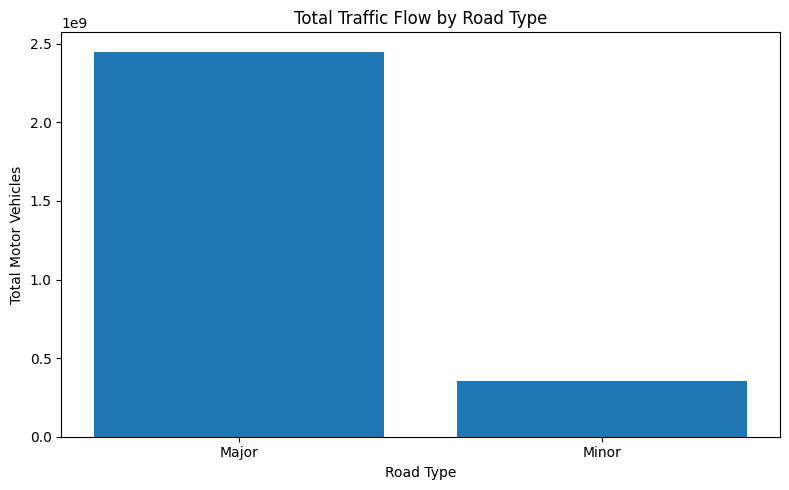

In [40]:
road_type_rows = traffic_by_road_type.collect()

road_types = [row["road_type"] for row in road_type_rows]
road_total_flow = [row["total_traffic_flow"] for row in road_type_rows]

plt.figure(figsize=(8, 5))
plt.bar(road_types, road_total_flow)

plt.title("Total Traffic Flow by Road Type")
plt.xlabel("Road Type")
plt.ylabel("Total Motor Vehicles")
plt.tight_layout()
plt.show()

## Analyse multi-vehicle traffic composition

In [43]:
vehicle_totals = traffic_clean.agg(
    spark_sum("pedal_cycles").alias("Pedal Cycles"),
    spark_sum("two_wheeled_motor_vehicles").alias("Two-Wheeled Motor Vehicles"),
    spark_sum("cars_and_taxis").alias("Cars and Taxis"),
    spark_sum("buses_and_coaches").alias("Buses and Coaches"),
    spark_sum("LGVs").alias("LGVs"),
    spark_sum("all_HGVs").alias("All HGVs")
)

vehicle_totals.show()

[Stage 145:>                                                        (0 + 8) / 8]

+------------+--------------------------+--------------+-----------------+------------+------------+
|Pedal Cycles|Two-Wheeled Motor Vehicles|Cars and Taxis|Buses and Coaches|        LGVs|    All HGVs|
+------------+--------------------------+--------------+-----------------+------------+------------+
| 1.4725308E7|               2.5049106E7| 2.162889184E9|      2.7069163E7|3.96796912E8|1.94261718E8|
+------------+--------------------------+--------------+-----------------+------------+------------+



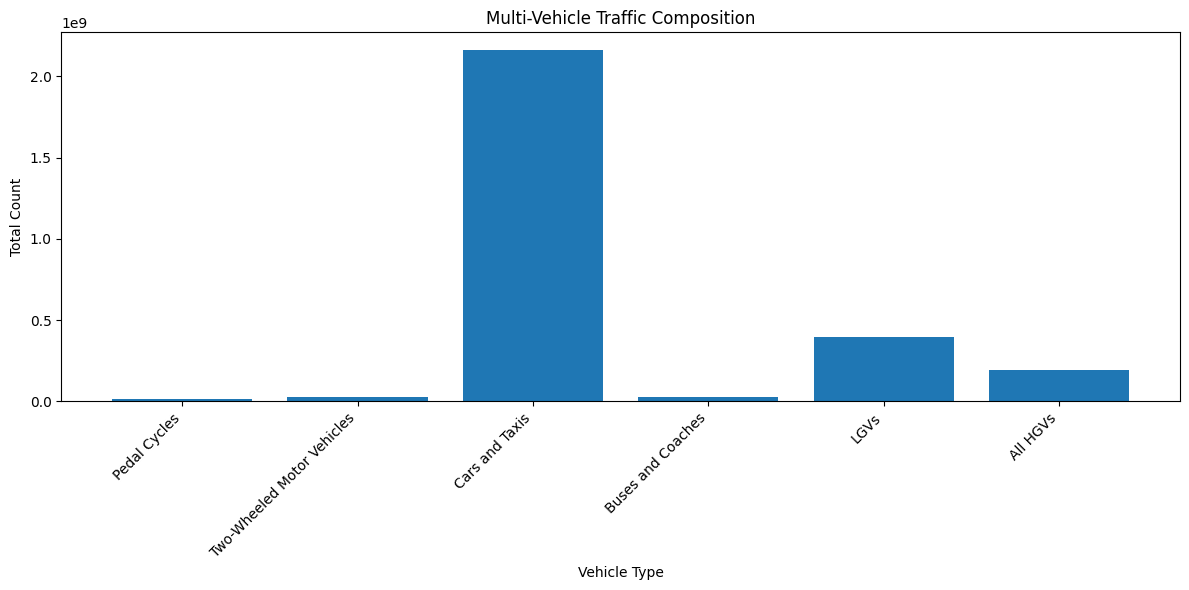

In [44]:
vehicle_row = vehicle_totals.collect()[0]

vehicle_types = [
    "Pedal Cycles",
    "Two-Wheeled Motor Vehicles",
    "Cars and Taxis",
    "Buses and Coaches",
    "LGVs",
    "All HGVs"
]

vehicle_values = [
    vehicle_row["Pedal Cycles"],
    vehicle_row["Two-Wheeled Motor Vehicles"],
    vehicle_row["Cars and Taxis"],
    vehicle_row["Buses and Coaches"],
    vehicle_row["LGVs"],
    vehicle_row["All HGVs"]
]

plt.figure(figsize=(12, 6))
plt.bar(vehicle_types, vehicle_values)

plt.title("Multi-Vehicle Traffic Composition")
plt.xlabel("Vehicle Type")
plt.ylabel("Total Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Year-wise Traffic Trend

This analysis shows how total traffic volume changes across different years. Spark aggregation is used because the dataset contains more than five million records.

In [3]:
traffic_by_year = traffic_labelled.groupBy("year") \
    .agg(
        spark_sum("all_motor_vehicles").alias("total_traffic_flow"),
        avg("all_motor_vehicles").alias("avg_traffic_flow"),
        count("*").alias("record_count")
    ) \
    .orderBy("year")

traffic_by_year.show()

+----+------------------+------------------+------------+
|year|total_traffic_flow|  avg_traffic_flow|record_count|
+----+------------------+------------------+------------+
|2000|      1.29879815E8| 714.9295142787943|      181668|
|2001|      1.38900997E8| 718.4137961353856|      193344|
|2002|      1.33478471E8|  632.006321082586|      211198|
|2003|      1.31965179E8| 592.7449491093005|      222634|
|2004|      1.24689879E8| 575.0025547495746|      216851|
|2005|      1.18937314E8| 590.7785697610308|      201323|
|2006|       1.2604567E8| 592.1473536845468|      212862|
|2007|      1.25199482E8| 606.5601887514595|      206409|
|2008|      1.35368068E8| 389.3243255680184|      347700|
|2009|      1.48584176E8|481.67799994813146|      308472|
|2010|      1.30559148E8| 638.9434460887949|      204336|
|2011|      1.08627271E8| 579.4567010199291|      187464|
|2012|      1.14768994E8| 608.2861307214484|      188676|
|2013|      1.11289616E8| 590.7092144373673|      188400|
|2014|       9

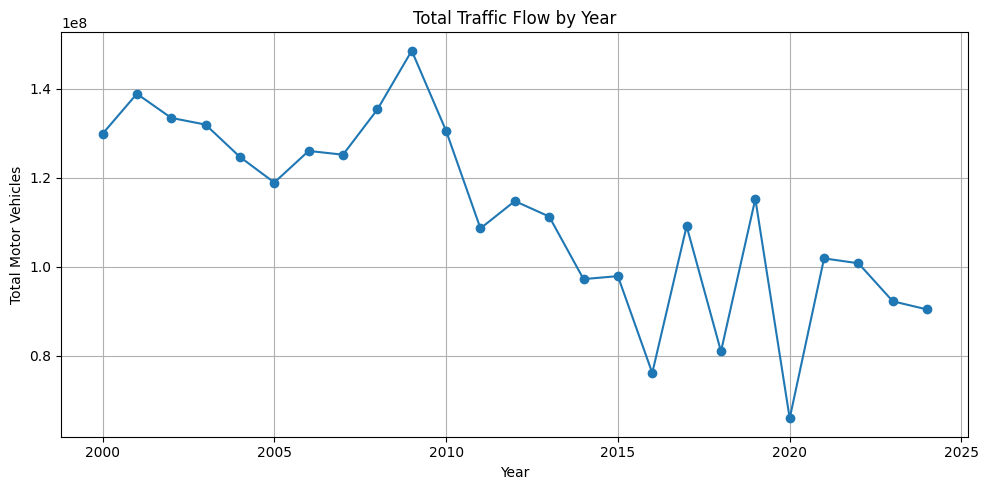

In [4]:
year_rows = traffic_by_year.collect()

years = [row["year"] for row in year_rows]
year_total_flow = [row["total_traffic_flow"] for row in year_rows]

plt.figure(figsize=(10, 5))
plt.plot(years, year_total_flow, marker="o")
plt.title("Total Traffic Flow by Year")
plt.xlabel("Year")
plt.ylabel("Total Motor Vehicles")
plt.grid(True)
plt.tight_layout()
plt.show()

### Scatter plot: geographical traffic distribution

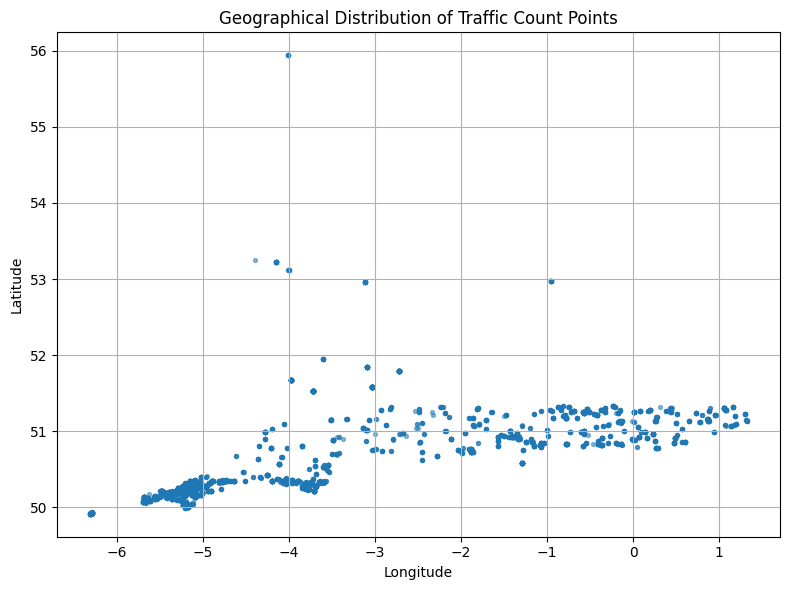

In [5]:
geo_sample = traffic_labelled.select(
    "latitude",
    "longitude",
    "all_motor_vehicles"
).dropna().limit(5000).collect()

latitudes = [row["latitude"] for row in geo_sample]
longitudes = [row["longitude"] for row in geo_sample]
traffic_values = [row["all_motor_vehicles"] for row in geo_sample]

plt.figure(figsize=(8, 6))
plt.scatter(longitudes, latitudes, s=8, alpha=0.5)

plt.title("Geographical Distribution of Traffic Count Points")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(True)
plt.tight_layout()
plt.show()

### Heatmap: average traffic by hour and road category

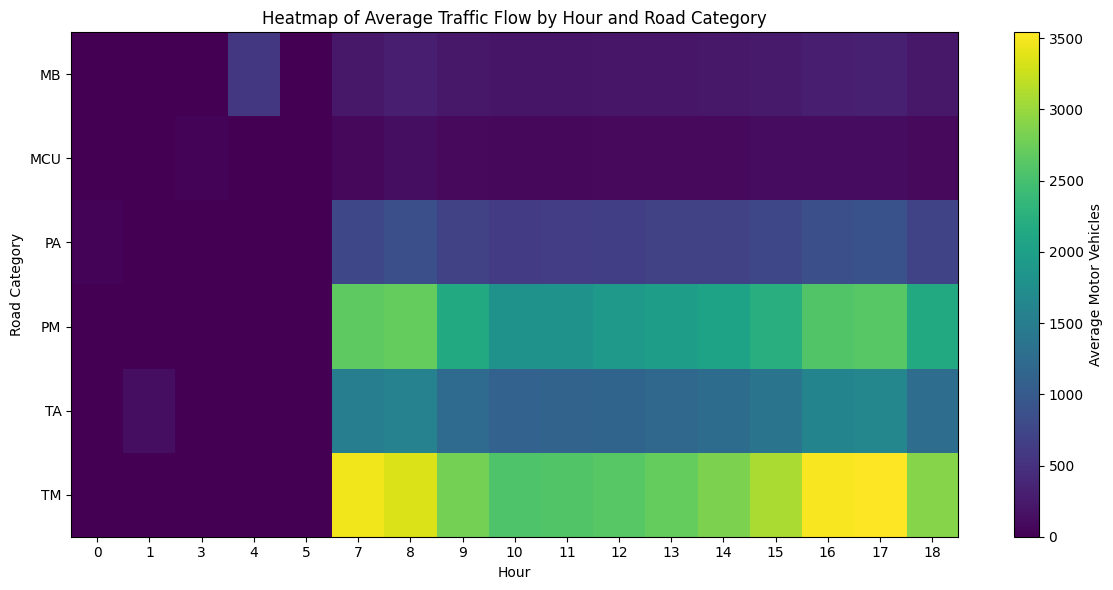

In [6]:
heatmap_data = traffic_labelled.groupBy("hour", "road_category") \
    .agg(avg("all_motor_vehicles").alias("avg_traffic_flow")) \
    .orderBy("hour", "road_category")

heatmap_rows = heatmap_data.collect()

hours = sorted(list(set([row["hour"] for row in heatmap_rows])))
categories = sorted(list(set([row["road_category"] for row in heatmap_rows])))

heatmap_matrix = np.zeros((len(categories), len(hours)))

for row in heatmap_rows:
    category_index = categories.index(row["road_category"])
    hour_index = hours.index(row["hour"])
    heatmap_matrix[category_index, hour_index] = row["avg_traffic_flow"]

plt.figure(figsize=(12, 6))
plt.imshow(heatmap_matrix, aspect="auto")

plt.title("Heatmap of Average Traffic Flow by Hour and Road Category")
plt.xlabel("Hour")
plt.ylabel("Road Category")
plt.xticks(range(len(hours)), hours)
plt.yticks(range(len(categories)), categories)
plt.colorbar(label="Average Motor Vehicles")
plt.tight_layout()
plt.show()

### Pie chart: normal vs anomaly distribution

In [7]:
anomaly_distribution = traffic_labelled.groupBy("congestion_anomaly") \
    .agg(count("*").alias("record_count")) \
    .orderBy("congestion_anomaly")

anomaly_distribution.show()

+------------------+------------+
|congestion_anomaly|record_count|
+------------------+------------+
|                 0|     4656250|
|                 1|      457475|
+------------------+------------+



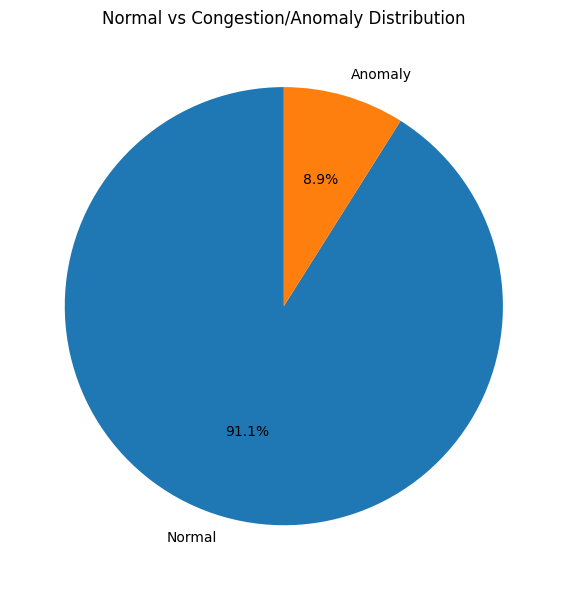

In [8]:
anomaly_rows = anomaly_distribution.collect()

labels = ["Normal" if row["congestion_anomaly"] == 0 else "Anomaly" for row in anomaly_rows]
sizes = [row["record_count"] for row in anomaly_rows]

plt.figure(figsize=(6, 6))
plt.pie(sizes, labels=labels, autopct="%1.1f%%", startangle=90)

plt.title("Normal vs Congestion/Anomaly Distribution")
plt.tight_layout()
plt.show()

In [ ]:
### Top 10 Busiest Road

In [9]:
top_roads = traffic_labelled.groupBy("road_name", "road_type") \
    .agg(
        spark_sum("all_motor_vehicles").alias("total_traffic_flow"),
        avg("all_motor_vehicles").alias("avg_traffic_flow"),
        count("*").alias("record_count")
    ) \
    .orderBy(col("total_traffic_flow").desc()) \
    .limit(10)

top_roads.show(truncate=False)

[Stage 38:============================>                            (8 + 8) / 16]

+---------+---------+------------------+------------------+------------+
|road_name|road_type|total_traffic_flow|avg_traffic_flow  |record_count|
+---------+---------+------------------+------------------+------------+
|U        |Minor    |1.25459188E8      |82.37110834044056 |1523097     |
|C        |Minor    |8.9434814E7       |128.73041763524748|694745      |
|M1       |Major    |7.9126331E7       |3535.5822609472743|22380       |
|A1       |Major    |6.7421161E7       |1747.5676775531363|38580       |
|M6       |Major    |6.7175661E7       |3247.0833816705335|20688       |
|M25      |Major    |6.52778E7         |4495.7162534435265|14520       |
|M4       |Major    |5.932268E7        |2994.280234201494 |19812       |
|M60      |Major    |4.6569957E7       |4172.935215053763 |11160       |
|M5       |Major    |4.5724996E7       |2919.859259259259 |15660       |
|A38      |Major    |4.4836625E7       |1242.1494071365248|36096       |
+---------+---------+------------------+-----------

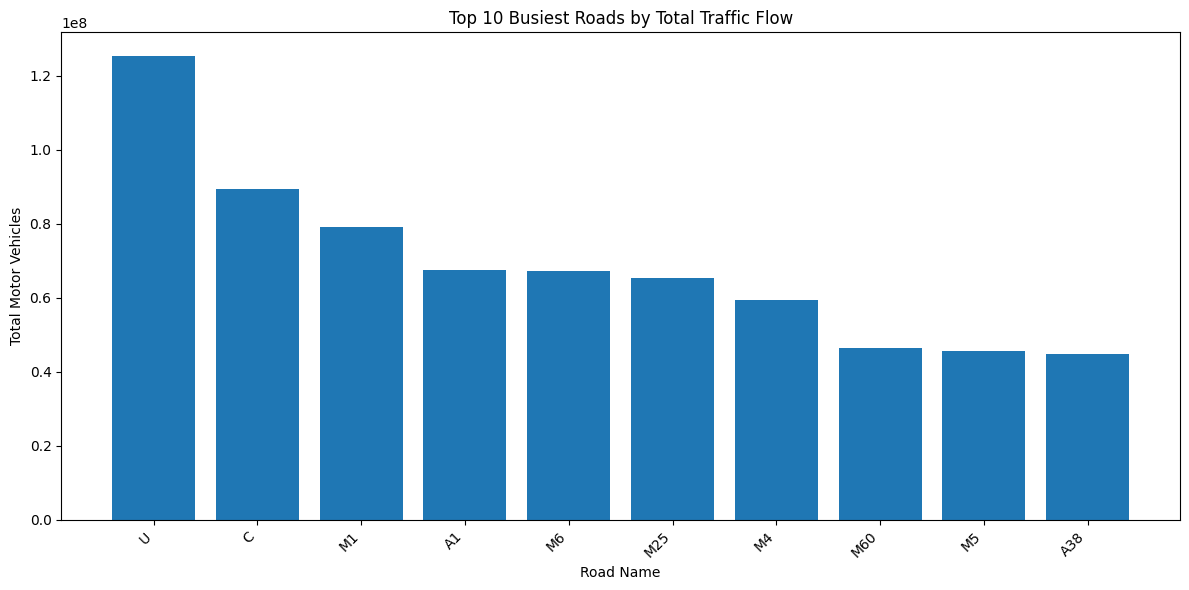

In [10]:
road_rows = top_roads.collect()

road_names = [row["road_name"] for row in road_rows]
road_total_flow = [row["total_traffic_flow"] for row in road_rows]

plt.figure(figsize=(12, 6))
plt.bar(road_names, road_total_flow)

plt.title("Top 10 Busiest Roads by Total Traffic Flow")
plt.xlabel("Road Name")
plt.ylabel("Total Motor Vehicles")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Outlier check for congestion/anomaly detection

In [45]:
traffic_clean.select("all_motor_vehicles").summary().show()

[Stage 157:=====================>                                   (3 + 5) / 8]

+-------+------------------+
|summary|all_motor_vehicles|
+-------+------------------+
|  count|           5113725|
|   mean| 548.7323062933576|
| stddev| 833.7378042624794|
|    min|               0.0|
|    25%|              51.0|
|    50%|             238.0|
|    75%|             664.0|
|    max|           10905.0|
+-------+------------------+



## IQR outlier threshold

In [46]:
q1, q3 = traffic_clean.approxQuantile(
    "all_motor_vehicles",
    [0.25, 0.75],
    0.01
)

iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Upper outlier threshold:", upper_bound)

[Stage 163:>                                                        (0 + 8) / 8]

Q1: 52.0
Q3: 659.0
IQR: 607.0
Upper outlier threshold: 1569.5


## Anomaly distribution

In [50]:
anomaly_count = traffic_clean.filter(
    col("all_motor_vehicles") > upper_bound
).count()

total_count = traffic_clean.count()

print("Total records:", total_count)
print("High-traffic anomaly records:", anomaly_count)
print("Anomaly percentage:", (anomaly_count / total_count) * 100)

[Stage 211:==============>                                          (2 + 6) / 8]

Total records: 5113725
High-traffic anomaly records: 457475
Anomaly percentage: 8.946022713384078


#### Using the IQR-based threshold, records with all_motor_vehicles greater than 1569.5 were labelled as high-traffic anomalies. The analysis identified 457,475 anomaly records out of 5,113,725 total records, representing approximately 8.95% of the cleaned dataset. This suggests that extreme congestion events are not the majority of the data, but they occur frequently enough to be meaningful for traffic monitoring.

# Creating anomaly label column

In [1]:
# Run after restarting the kernel 

from pyspark.sql import SparkSession
from pyspark.sql.functions import col, when, avg, count, sum as spark_sum

spark = SparkSession.builder \
    .appName("Spatiotemporal_Congestion_Anomaly_Detection") \
    .config("spark.sql.shuffle.partitions", "4") \
    .config("spark.driver.memory", "2g") \
    .getOrCreate()

traffic_clean = spark.read.parquet(
    "hdfs:///traffic_data/cleaned_traffic_counts_parquet"
)

upper_bound = 1569.5

traffic_clean = traffic_clean.withColumn(
    "congestion_anomaly",
    when(col("all_motor_vehicles") > upper_bound, 1).otherwise(0)
)

print("Spark restarted and cleaned dataset loaded.")
print("Rows:", traffic_clean.count())
print("Columns:", len(traffic_clean.columns))

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/05/14 14:18:08 WARN Utils: Your hostname, LAPTOP-N51U7423, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/05/14 14:18:08 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/05/14 14:18:10 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
                                                                                

Spark restarted and cleaned dataset loaded.


[Stage 1:===================================>                     (10 + 6) / 16]

Rows: 5113725
Columns: 36


In [ ]:
from pyspark.sql.functions import when

traffic_clean = traffic_clean.withColumn(
    "congestion_anomaly",
    when(col("all_motor_vehicles") > upper_bound, 1).otherwise(0)
)

traffic_clean.select(
    "all_motor_vehicles",
    "congestion_anomaly"
).show(10)

In [2]:
traffic_clean.filter(
    col("congestion_anomaly") == 1
).select(
    "count_date",
    "hour",
    "region_name",
    "local_authority_name",
    "road_name",
    "road_type",
    "all_motor_vehicles",
    "congestion_anomaly"
).show(10, truncate=False)

+----------+----+-----------+--------------------+---------+---------+------------------+------------------+
|count_date|hour|region_name|local_authority_name|road_name|road_type|all_motor_vehicles|congestion_anomaly|
+----------+----+-----------+--------------------+---------+---------+------------------+------------------+
|2021-09-15|12  |Scotland   |North Lanarkshire   |M80      |Major    |2041.0            |1                 |
|2021-09-15|18  |Scotland   |North Lanarkshire   |M80      |Major    |1852.0            |1                 |
|2021-09-15|10  |Scotland   |North Lanarkshire   |M80      |Major    |1852.0            |1                 |
|2021-09-15|7   |Scotland   |North Lanarkshire   |M80      |Major    |2738.0            |1                 |
|2021-09-15|18  |Scotland   |North Lanarkshire   |M80      |Major    |2062.0            |1                 |
|2021-09-15|10  |Scotland   |North Lanarkshire   |M80      |Major    |1912.0            |1                 |
|2000-06-09|11  |Wa

## Dataset with congestion anomaly label 


In [2]:
traffic_clean.write.mode("overwrite").parquet(
    "hdfs:///traffic_data/traffic_with_anomaly_label"
)

print("Dataset with congestion anomaly label saved to HDFS.")

26/05/14 12:29:24 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
[Stage 4:==============================================>          (13 + 3) / 16]

Dataset with congestion anomaly label saved to HDFS.


traffic_labelled = spark.read.parquet(
    "hdfs:///traffic_data/traffic_with_anomaly_label"
)

print("Rows:", traffic_labelled.count())
print("Columns:", len(traffic_labelled.columns))

traffic_labelled.select(
    "all_motor_vehicles",
    "congestion_anomaly"
).show(10)

In [4]:
traffic_labelled.groupBy("congestion_anomaly") \
    .count() \
    .orderBy("congestion_anomaly") \
    .show()

+------------------+-------+
|congestion_anomaly|  count|
+------------------+-------+
|                 0|4656250|
|                 1| 457475|
+------------------+-------+



# Feature engineering for modelling

In [6]:
model_df = traffic_labelled.select(
    "year",
    "hour",
    "region_id",
    "local_authority_id",
    "road_type",
    "pedal_cycles",
    "two_wheeled_motor_vehicles",
    "cars_and_taxis",
    "buses_and_coaches",
    "LGVs",
    "all_HGVs",
    "all_motor_vehicles",
    "congestion_anomaly"
)

model_df.show(5)
model_df.printSchema()

+----+----+---------+------------------+---------+------------+--------------------------+--------------+-----------------+----+--------+------------------+------------------+
|year|hour|region_id|local_authority_id|road_type|pedal_cycles|two_wheeled_motor_vehicles|cars_and_taxis|buses_and_coaches|LGVs|all_HGVs|all_motor_vehicles|congestion_anomaly|
+----+----+---------+------------------+---------+------------+--------------------------+--------------+-----------------+----+--------+------------------+------------------+
|2004|  10|        1|                 1|    Major|         5.0|                       1.0|          28.0|              4.0| 4.0|     4.0|              41.0|                 0|
|2004|  14|        1|                 1|    Major|         9.0|                       3.0|          19.0|              1.0| 8.0|     6.0|              37.0|                 0|
|2004|  12|        1|                 1|    Major|         9.0|                       1.0|          15.0|              2

In [7]:
top_count_points = traffic_labelled.groupBy(
    "count_point_id",
    "region_name",
    "local_authority_name",
    "road_name",
    "road_type"
).agg(
    spark_sum("all_motor_vehicles").alias("total_traffic_flow"),
    count("*").alias("record_count")
).orderBy(
    col("total_traffic_flow").desc()
)

top_count_points.show(10, truncate=False)

+--------------+-----------+--------------------+---------+---------+------------------+------------+
|count_point_id|region_name|local_authority_name|road_name|road_type|total_traffic_flow|record_count|
+--------------+-----------+--------------------+---------+---------+------------------+------------+
|37918         |South East |Surrey              |M25      |Major    |3285655.0         |576         |
|16051         |North West |Bury                |M60      |Major    |3010652.0         |528         |
|6053          |North West |Bury                |M60      |Major    |2848585.0         |504         |
|7902          |South East |Buckinghamshire     |M25      |Major    |2835043.0         |480         |
|56037         |South East |Surrey              |M25      |Major    |2776443.0         |552         |
|7901          |South East |Surrey              |M25      |Major    |2616316.0         |480         |
|46050         |North West |Salford             |M60      |Major    |2552010.0    

In [8]:
selected_count_point = 37918

model_data = traffic_labelled.filter(
    col("count_point_id") == selected_count_point
).select(
    "count_date",
    "hour",
    "cars_and_taxis",
    "buses_and_coaches",
    "LGVs",
    "all_HGVs",
    "all_motor_vehicles",
    "congestion_anomaly"
).orderBy(
    "count_date",
    "hour"
)

print("Selected count point:", selected_count_point)
print("Rows for selected count point:", model_data.count())

model_data.show(10, truncate=False)

Selected count point: 37918


Rows for selected count point: 576


[Stage 20:============================>                            (8 + 8) / 16]

+----------+----+--------------+-----------------+-----+--------+------------------+------------------+
|count_date|hour|cars_and_taxis|buses_and_coaches|LGVs |all_HGVs|all_motor_vehicles|congestion_anomaly|
+----------+----+--------------+-----------------+-----+--------+------------------+------------------+
|2000-05-17|7   |5351.0        |19.0             |611.0|450.0   |6500.0            |1                 |
|2000-05-17|7   |4673.0        |31.0             |873.0|803.0   |6413.0            |1                 |
|2000-05-17|8   |4732.0        |21.0             |654.0|603.0   |6045.0            |1                 |
|2000-05-17|8   |4731.0        |18.0             |332.0|398.0   |5554.0            |1                 |
|2000-05-17|9   |4229.0        |42.0             |446.0|615.0   |5358.0            |1                 |
|2000-05-17|9   |5052.0        |42.0             |542.0|659.0   |6323.0            |1                 |
|2000-05-17|10  |4393.0        |39.0             |612.0|746.0   

### Checking the total Row count for 10 count points

In [9]:
top_10_count_points = [
    row["count_point_id"]
    for row in top_count_points.select("count_point_id").limit(10).collect()
]

print("Top 10 count point IDs:")
print(top_10_count_points)

[Stage 21:================================>                        (9 + 7) / 16]

Top 10 count point IDs:
[37918, 16051, 6053, 7902, 56037, 7901, 46050, 36029, 16012, 27923]


In [10]:
model_data_top10 = traffic_labelled.filter(
    col("count_point_id").isin(top_10_count_points)
).select(
    "count_point_id",
    "count_date",
    "hour",
    "cars_and_taxis",
    "buses_and_coaches",
    "LGVs",
    "all_HGVs",
    "all_motor_vehicles",
    "congestion_anomaly"
).orderBy(
    "count_point_id",
    "count_date",
    "hour"
)

print("Rows in top 10 modelling dataset:", model_data_top10.count())
model_data_top10.show(10, truncate=False)

Rows in top 10 modelling dataset: 4944


[Stage 27:============================>                            (8 + 8) / 16]

+--------------+----------+----+--------------+-----------------+-----+--------+------------------+------------------+
|count_point_id|count_date|hour|cars_and_taxis|buses_and_coaches|LGVs |all_HGVs|all_motor_vehicles|congestion_anomaly|
+--------------+----------+----+--------------+-----------------+-----+--------+------------------+------------------+
|6053          |2000-06-19|7   |4049.0        |18.0             |786.0|759.0   |5629.0            |1                 |
|6053          |2000-06-19|7   |4480.0        |9.0              |890.0|869.0   |6271.0            |1                 |
|6053          |2000-06-19|8   |4699.0        |24.0             |794.0|833.0   |6372.0            |1                 |
|6053          |2000-06-19|8   |3917.0        |18.0             |622.0|716.0   |5284.0            |1                 |
|6053          |2000-06-19|9   |3443.0        |43.0             |775.0|925.0   |5199.0            |1                 |
|6053          |2000-06-19|9   |3440.0        |2

In [11]:
model_data_top10.groupBy("count_point_id") \
    .count() \
    .orderBy("count_point_id") \
    .show(20)

[Stage 28:============================>                            (8 + 8) / 16]

+--------------+-----+
|count_point_id|count|
+--------------+-----+
|          6053|  504|
|          7901|  480|
|          7902|  480|
|         16012|  528|
|         16051|  528|
|         27923|  384|
|         36029|  504|
|         37918|  576|
|         46050|  408|
|         56037|  552|
+--------------+-----+



In [12]:
model_rows = model_data_top10.collect()

print("Rows collected for CNN-LSTM:", len(model_rows))
print(model_rows[0])

[Stage 32:============================>                            (8 + 8) / 16]

Rows collected for CNN-LSTM: 4944
Row(count_point_id=6053, count_date=datetime.date(2000, 6, 19), hour=7, cars_and_taxis=4480.0, buses_and_coaches=9.0, LGVs=890.0, all_HGVs=869.0, all_motor_vehicles=6271.0, congestion_anomaly=1)


### Checking the row for 100 count point

In [14]:
top_100_count_points = [
    row["count_point_id"]
    for row in top_count_points.select("count_point_id").limit(100).collect()
]

print("Number of selected count points:", len(top_100_count_points))
print(" 100 count point IDs:", top_100_count_points[:100])

[Stage 38:============================>                            (8 + 8) / 16]

Number of selected count points: 100
First 10 count point IDs: [37918, 16051, 6053, 7902, 56037, 7901, 46050, 36029, 16012, 27923, 57740, 6028, 99526, 27085, 46011, 48064, 7824, 46008, 48582, 38523, 17838, 9041, 26007, 47578, 48040, 70270, 6007, 36053, 27866, 48371, 26010, 74865, 6040, 46010, 36038, 17875, 99417, 36052, 56047, 73269, 48089, 16008, 26055, 56002, 17800, 46001, 56051, 26047, 7903, 6036, 56054, 6013, 16005, 38020, 47876, 47901, 16092, 6429, 46012, 48090, 38718, 16013, 46019, 6178, 17022, 56681, 16044, 7701, 17918, 99612, 99511, 6058, 18626, 16039, 26013, 36055, 56048, 26053, 56038, 7054, 26044, 26014, 17739, 50501, 36002, 27883, 27879, 36113, 26299, 17793, 26434, 38022, 38021, 16027, 46037, 38083, 38113, 46039, 6047, 36006]


In [18]:
model_data_top100 = traffic_labelled.filter(
    col("count_point_id").isin(top_100_count_points)
).select(
    "count_point_id",
    "count_date",
    "hour",
    "pedal_cycles",
    "two_wheeled_motor_vehicles",
    "cars_and_taxis",
    "buses_and_coaches",
    "LGVs",
    "all_HGVs",
    "all_motor_vehicles",
    "congestion_anomaly"
).orderBy(
    "count_point_id",
    "count_date",
    "hour"
)

print("Rows in top 100 modelling dataset:", model_data_top100.count())
model_data_top100.show(5, truncate=False)

Rows in top 100 modelling dataset: 49464


[Stage 52:============================>                            (8 + 8) / 16]

+--------------+----------+----+------------+--------------------------+--------------+-----------------+-----+--------+------------------+------------------+
|count_point_id|count_date|hour|pedal_cycles|two_wheeled_motor_vehicles|cars_and_taxis|buses_and_coaches|LGVs |all_HGVs|all_motor_vehicles|congestion_anomaly|
+--------------+----------+----+------------+--------------------------+--------------+-----------------+-----+--------+------------------+------------------+
|6007          |2000-10-31|7   |0.0         |5.0                       |3212.0        |6.0              |603.0|458.0   |4284.0            |1                 |
|6007          |2000-10-31|7   |0.0         |2.0                       |2226.0        |19.0             |491.0|508.0   |3246.0            |1                 |
|6007          |2000-10-31|8   |0.0         |0.0                       |2640.0        |5.0              |594.0|660.0   |3899.0            |1                 |
|6007          |2000-10-31|8   |0.0         |4

In [19]:
model_rows_top100 = model_data_top100.collect()

print("Rows collected for CNN-LSTM:", len(model_rows_top100))
print(model_rows_top100[0])

Rows collected for CNN-LSTM: 49464
Row(count_point_id=6007, count_date=datetime.date(2000, 10, 31), hour=7, pedal_cycles=0.0, two_wheeled_motor_vehicles=5.0, cars_and_taxis=3212.0, buses_and_coaches=6.0, LGVs=603.0, all_HGVs=458.0, all_motor_vehicles=4284.0, congestion_anomaly=1)


### Converting the collected rows into a numeric array for CNN-LSTM

In [20]:
import numpy as np

feature_columns = [
    "hour",
    "count_point_id",
    "pedal_cycles",
    "two_wheeled_motor_vehicles",
    "cars_and_taxis",
    "buses_and_coaches",
    "LGVs",
    "all_HGVs"
]

target_column = "all_motor_vehicles"

data_array = np.array([
    [
        float(row["hour"]),
        float(row["count_point_id"]),
        float(row["pedal_cycles"]),
        float(row["two_wheeled_motor_vehicles"]),
        float(row["cars_and_taxis"]),
        float(row["buses_and_coaches"]),
        float(row["LGVs"]),
        float(row["all_HGVs"]),
        float(row["all_motor_vehicles"])
    ]
    for row in model_rows_top100
])

print("Data array shape:", data_array.shape)
print("Number of input features:", len(feature_columns))
print("Target column:", target_column)
print("First row:", data_array[0])

Data array shape: (49464, 9)
Number of input features: 8
Target column: all_motor_vehicles
First row: [7.000e+00 6.007e+03 0.000e+00 5.000e+00 3.212e+03 6.000e+00 6.030e+02
 4.580e+02 4.284e+03]


## scale the data before CNN-LSTM

In [22]:
import sys
!{sys.executable} -m pip install scikit-learn --default-timeout=300

Defaulting to user installation because normal site-packages is not writeable
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 44.1 kB/s eta 0:00:0000:0100:07
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 309.1/309.1 KB 37.7 kB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.7/37.7 MB 6.5 MB/s eta 0:00:0000:0100:01m


In [23]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

scaled_data = scaler.fit_transform(data_array)

print("Scaled data shape:", scaled_data.shape)
print("First scaled row:", scaled_data[0])

Scaled data shape: (49464, 9)
First scaled row: [0.         0.         0.         0.01355014 0.35641367 0.00757576
 0.10376871 0.17019695 0.39284732]


## time-series sequences for CNN-LSTM

In [24]:
def create_sequences(data, window_size=8):
    X = []
    y = []

    for i in range(len(data) - window_size):
        X.append(data[i:i + window_size, :-1])   # first 8 columns = input features
        y.append(data[i + window_size, -1])      # last column = target all_motor_vehicles

    return np.array(X), np.array(y)


window_size = 8

X, y = create_sequences(scaled_data, window_size)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (49456, 8, 8)
y shape: (49456,)


## Split the sequence data into training and testing sets

In [25]:
train_size = int(len(X) * 0.8)

X_train = X[:train_size]
X_test = X[train_size:]

y_train = y[:train_size]
y_test = y[train_size:]

print("Training samples:", X_train.shape)
print("Testing samples:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training samples: (39564, 8, 8)
Testing samples: (9892, 8, 8)
Training target: (39564,)
Testing target: (9892,)


# Creating the Baseline Model (Linear Regression)

In [26]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Flatten sequence data for baseline ML model
X_train_flat = X_train.reshape(X_train.shape[0], X_train.shape[1] * X_train.shape[2])
X_test_flat = X_test.reshape(X_test.shape[0], X_test.shape[1] * X_test.shape[2])

baseline_model = LinearRegression()
baseline_model.fit(X_train_flat, y_train)

baseline_pred = baseline_model.predict(X_test_flat)

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))

print("Baseline Linear Regression Results")
print("MAE:", baseline_mae)
print("RMSE:", baseline_rmse)

Baseline Linear Regression Results
MAE: 0.047535587789374306
RMSE: 0.06433778083437136


# Build the LSTM model

In [28]:
import sys
!{sys.executable} -m pip install tensorflow-cpu --default-timeout=300

Defaulting to user installation because normal site-packages is not writeable
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 273.6/273.6 MB 2.0 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 66.5 kB/s eta 0:00:0000:0100:03
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 1.1 MB/s eta 0:00:0000:0100:010m
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.8/135.8 KB 1.3 MB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.9/71.9 KB 1.3 MB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 113.6/113.6 KB 1.2 MB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 324.3/324.3 KB 919.1 kB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 1.8 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 6.8 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.5/57.5 KB 4.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [29]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

lstm_model = Sequential([
    LSTM(64, input_shape=(X_train.shape[1], X_train.shape[2])),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(1)
])

lstm_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_lstm = lstm_model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

I0000 00:00:1778744866.618074   13604 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/home/biraj01/.local/lib/python3.10/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/20
990/990 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - loss: 0.0061 - mae: 0.0562 - val_loss: 0.0041 - val_mae: 0.0481
Epoch 2/20
990/990 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - loss: 0.0041 - mae: 0.0479 - val_loss: 0.0040 - val_mae: 0.0467
Epoch 3/20
990/990 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - loss: 0.0039 - mae: 0.0464 - val_loss: 0.0039 - val_mae: 0.0460
Epoch 4/20
990/990 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - loss: 0.0038 - mae: 0.0456 - val_loss: 0.0039 - val_mae: 0.0456
Epoch 5/20
990/990 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - loss: 0.0037 - mae: 0.0452 - val_loss: 0.0041 - val_mae: 0.0468
Epoch 6/20
990/990 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - loss: 0.0037 - mae: 0.0450 - val_loss: 0.0039 - val_mae: 0.0457
Epoch 7/20
990/990 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - loss: 0.0036 - mae: 0.0446 - val_loss: 0.0038 - val_mae: 0.0453
Epoch 8/20
990/990 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - loss: 0.0036 - mae: 0.0446 - val_loss: 0.0039 - val_mae: 0.0450
Epoch 9/20
990/990 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - l

In [31]:
import matplotlib.pyplot as plt

print("Matplotlib ready.")

Matplotlib ready.


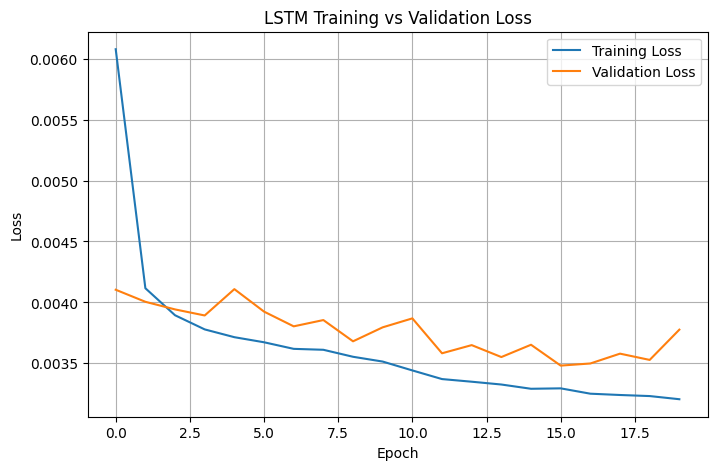

In [32]:
plt.figure(figsize=(8, 5))
plt.plot(history_lstm.history["loss"], label="Training Loss")
plt.plot(history_lstm.history["val_loss"], label="Validation Loss")

plt.title("LSTM Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

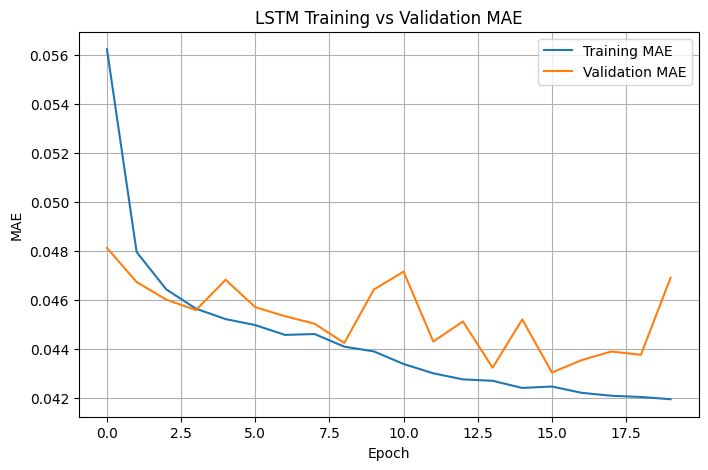

In [33]:
plt.figure(figsize=(8, 5))

plt.plot(history_lstm.history["mae"], label="Training MAE")
plt.plot(history_lstm.history["val_mae"], label="Validation MAE")

plt.title("LSTM Training vs Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.legend()
plt.grid(True)
plt.show()

In [35]:
lstm_pred = lstm_model.predict(X_test)

lstm_mae = mean_absolute_error(y_test, lstm_pred)
lstm_rmse = np.sqrt(mean_squared_error(y_test, lstm_pred))

print("LSTM Test Results")
print("MAE:", lstm_mae)
print("RMSE:", lstm_rmse)

310/310 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
LSTM Test Results
MAE: 0.04332032401345952
RMSE: 0.059266559481439635


# Building the CNN-LSTM model

In [36]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Bidirectional, LSTM, Dense, Dropout

cnn_bilstm_model = Sequential([
    Conv1D(
        filters=64,
        kernel_size=3,
        activation="relu",
        padding="same",
        input_shape=(X_train.shape[1], X_train.shape[2])
    ),
    MaxPooling1D(pool_size=2),

    Conv1D(
        filters=128,
        kernel_size=3,
        activation="relu",
        padding="same"
    ),

    Bidirectional(
        LSTM(64)
    ),

    Dropout(0.3),

    Dense(32, activation="relu"),
    Dense(1)
])

cnn_bilstm_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

cnn_bilstm_model.summary()

/home/biraj01/.local/lib/python3.10/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 8, 64)          │         1,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 4, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 4, 128)         │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 129,281 (505.00 KB)

 Trainable params: 129,281 (505.00 KB)

 Non-trainable params: 0 (0.00 B)

In [37]:
history_cnn_bilstm = cnn_bilstm_model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/20
990/990 ━━━━━━━━━━━━━━━━━━━━ 12s 9ms/step - loss: 0.0058 - mae: 0.0552 - val_loss: 0.0041 - val_mae: 0.0467
Epoch 2/20
990/990 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - loss: 0.0040 - mae: 0.0470 - val_loss: 0.0039 - val_mae: 0.0452
Epoch 3/20
990/990 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - loss: 0.0036 - mae: 0.0444 - val_loss: 0.0040 - val_mae: 0.0485
Epoch 4/20
990/990 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - loss: 0.0034 - mae: 0.0433 - val_loss: 0.0036 - val_mae: 0.0437
Epoch 5/20
990/990 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - loss: 0.0034 - mae: 0.0431 - val_loss: 0.0036 - val_mae: 0.0447


In [38]:
cnn_bilstm_pred = cnn_bilstm_model.predict(X_test)

cnn_bilstm_mae = mean_absolute_error(y_test, cnn_bilstm_pred)
cnn_bilstm_rmse = np.sqrt(mean_squared_error(y_test, cnn_bilstm_pred))

print("CNN-BiLSTM Test Results")
print("MAE:", cnn_bilstm_mae)
print("RMSE:", cnn_bilstm_rmse)

310/310 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
CNN-BiLSTM Test Results
MAE: 0.04979094801812439
RMSE: 0.06750598830656898


In [39]:
def calculate_mape(y_true, y_pred):
    y_true = np.array(y_true).reshape(-1)
    y_pred = np.array(y_pred).reshape(-1)

    # Avoid division by zero
    non_zero_index = y_true != 0

    return np.mean(
        np.abs((y_true[non_zero_index] - y_pred[non_zero_index]) / y_true[non_zero_index])
    ) * 100


baseline_mape = calculate_mape(y_test, baseline_pred)
lstm_mape = calculate_mape(y_test, lstm_pred)
cnn_bilstm_mape = calculate_mape(y_test, cnn_bilstm_pred)

baseline_accuracy_like = 100 - baseline_mape
lstm_accuracy_like = 100 - lstm_mape
cnn_bilstm_accuracy_like = 100 - cnn_bilstm_mape

print("Baseline Linear Regression")
print("MAPE:", baseline_mape)
print("Accuracy-like %:", baseline_accuracy_like)

print("\nLSTM")
print("MAPE:", lstm_mape)
print("Accuracy-like %:", lstm_accuracy_like)

print("\nCNN-BiLSTM")
print("MAPE:", cnn_bilstm_mape)
print("Accuracy-like %:", cnn_bilstm_accuracy_like)

Baseline Linear Regression
MAPE: 12.241011239363964
Accuracy-like %: 87.75898876063604

LSTM
MAPE: 10.938827362994054
Accuracy-like %: 89.06117263700594

CNN-BiLSTM
MAPE: 12.48882372318107
Accuracy-like %: 87.51117627681893


## Model comparison bar chart

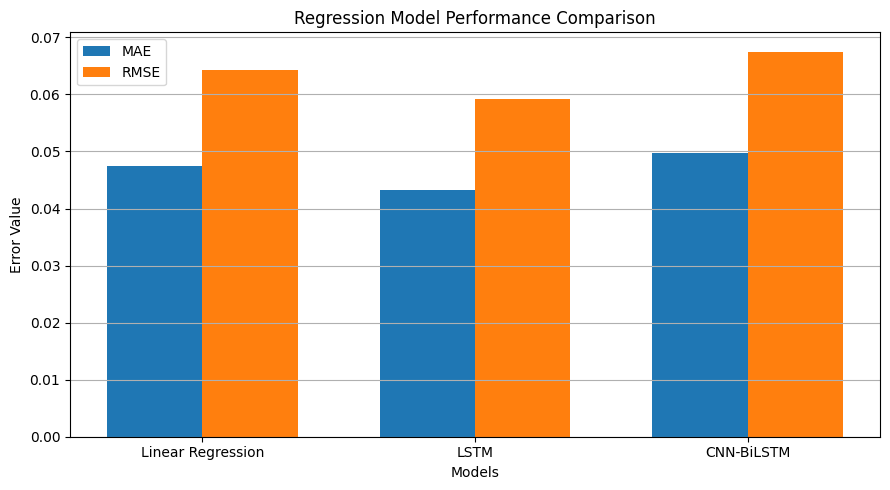

In [40]:
models = ["Linear Regression", "LSTM", "CNN-BiLSTM"]

mae_scores = [
    baseline_mae,
    lstm_mae,
    cnn_bilstm_mae
]

rmse_scores = [
    baseline_rmse,
    lstm_rmse,
    cnn_bilstm_rmse
]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width/2, mae_scores, width, label="MAE")
plt.bar(x + width/2, rmse_scores, width, label="RMSE")

plt.xlabel("Models")
plt.ylabel("Error Value")
plt.title("Regression Model Performance Comparison")
plt.xticks(x, models)
plt.legend()
plt.grid(axis="y")
plt.tight_layout()
plt.show()

## Actual vs Predicted graph for LSTM

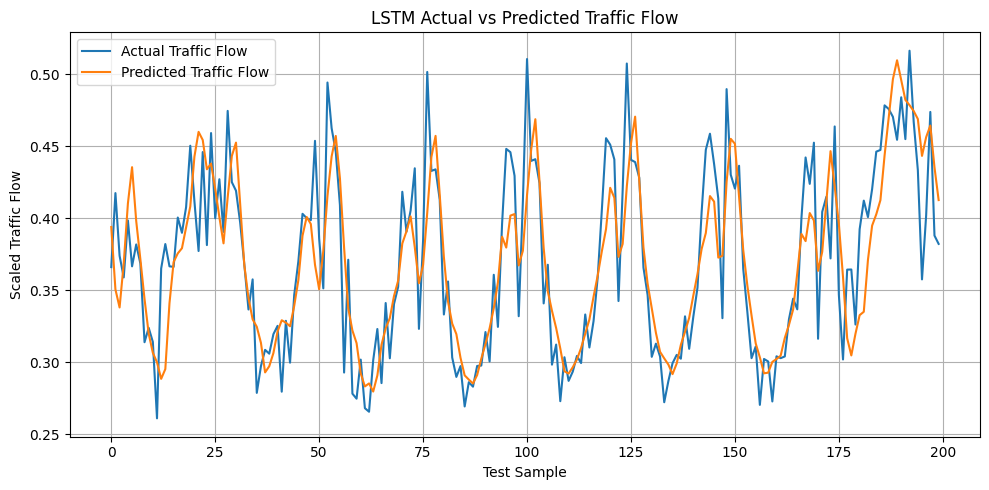

In [41]:
plt.figure(figsize=(10, 5))

plt.plot(y_test[:200], label="Actual Traffic Flow")
plt.plot(lstm_pred[:200], label="Predicted Traffic Flow")

plt.title("LSTM Actual vs Predicted Traffic Flow")
plt.xlabel("Test Sample")
plt.ylabel("Scaled Traffic Flow")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Actual vs Predicted graph for CNN-BiLSTM

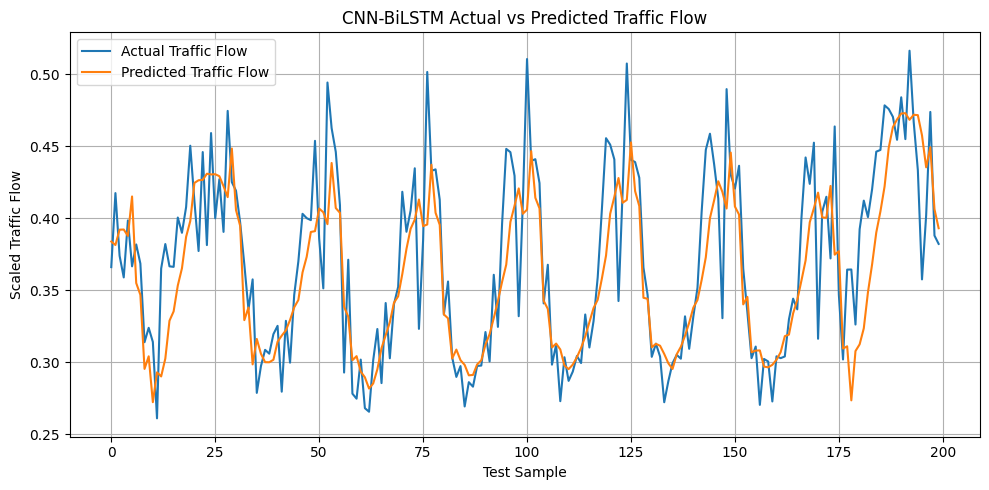

In [43]:
plt.figure(figsize=(10, 5))

plt.plot(y_test[:200], label="Actual Traffic Flow")
plt.plot(cnn_bilstm_pred[:200], label="Predicted Traffic Flow")

plt.title("CNN-BiLSTM Actual vs Predicted Traffic Flow")
plt.xlabel("Test Sample")
plt.ylabel("Scaled Traffic Flow")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Congestion and Anomaly Detection Classification
In this section, the target variable is `congestion_anomaly`, where 0 represents normal traffic and 1 represents high-traffic congestion/anomaly. Unlike the previous regression models that predicted `all_motor_vehicles`, this classification task predicts whether a traffic record belongs to the normal or congestion/anomaly class.

In [45]:
# Prepare anomaly labels for sequence classification

anomaly_labels = np.array([
    int(row["congestion_anomaly"])
    for row in model_rows_top100
])

# Align labels with sequence data
y_class = anomaly_labels[window_size:]

print("Classification target shape:", y_class.shape)
print("Class values:", np.unique(y_class, return_counts=True))

Classification target shape: (49456,)
Class values: (array([0, 1]), array([  201, 49255]))


In [3]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col
import numpy as np
import matplotlib.pyplot as plt

spark = SparkSession.builder \
    .appName("Classification_Anomaly_Detection") \
    .config("spark.sql.shuffle.partitions", "4") \
    .config("spark.driver.memory", "3g") \
    .getOrCreate()

traffic_labelled = spark.read.parquet(
    "hdfs:///traffic_data/traffic_with_anomaly_label"
)

print("Labelled dataset loaded.")
print("Rows:", traffic_labelled.count())
print("Columns:", len(traffic_labelled.columns))

26/05/14 14:20:21 WARN SparkSession: Using an existing Spark session; only runtime SQL configurations will take effect.


Labelled dataset loaded.
Rows: 5113725
Columns: 36


In [4]:
normal_data = traffic_labelled.filter(
    col("congestion_anomaly") == 0
).limit(50000)

anomaly_data = traffic_labelled.filter(
    col("congestion_anomaly") == 1
).limit(50000)

classification_data = normal_data.union(anomaly_data)

print("Balanced classification dataset rows:", classification_data.count())

classification_data.groupBy("congestion_anomaly").count().show()

Balanced classification dataset rows: 100000


[Stage 14:======================================>                 (11 + 5) / 16]

+------------------+-----+
|congestion_anomaly|count|
+------------------+-----+
|                 0|50000|
|                 1|50000|
+------------------+-----+



### convert the balanced Spark dataset into a local NumPy array for classification

In [5]:
classification_rows = classification_data.select(
    "hour",
    "count_point_id",
    "pedal_cycles",
    "two_wheeled_motor_vehicles",
    "cars_and_taxis",
    "buses_and_coaches",
    "LGVs",
    "all_HGVs",
    "congestion_anomaly"
).collect()

print("Rows collected for classification:", len(classification_rows))
print(classification_rows[0])

Rows collected for classification: 100000
Row(hour=10, count_point_id=51, pedal_cycles=5.0, two_wheeled_motor_vehicles=1.0, cars_and_taxis=28.0, buses_and_coaches=4.0, LGVs=4.0, all_HGVs=4.0, congestion_anomaly=0)


In [6]:
classification_array = np.array([
    [
        float(row["hour"]),
        float(row["count_point_id"]),
        float(row["pedal_cycles"]),
        float(row["two_wheeled_motor_vehicles"]),
        float(row["cars_and_taxis"]),
        float(row["buses_and_coaches"]),
        float(row["LGVs"]),
        float(row["all_HGVs"]),
        int(row["congestion_anomaly"])
    ]
    for row in classification_rows
])

X_class = classification_array[:, :-1]
y_class = classification_array[:, -1].astype(int)

print("X_class shape:", X_class.shape)
print("y_class shape:", y_class.shape)
print("Class counts:", np.unique(y_class, return_counts=True))

X_class shape: (100000, 8)
y_class shape: (100000,)
Class counts: (array([0, 1]), array([50000, 50000]))


### MinMax Scaler

In [7]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

class_scaler = MinMaxScaler()

X_class_scaled = class_scaler.fit_transform(X_class)

X_class_train, X_class_test, y_class_train, y_class_test = train_test_split(
    X_class_scaled,
    y_class,
    test_size=0.2,
    random_state=42,
    stratify=y_class
)

print("X_class_train:", X_class_train.shape)
print("X_class_test:", X_class_test.shape)
print("y_class_train:", y_class_train.shape)
print("y_class_test:", y_class_test.shape)

print("Train class counts:", np.unique(y_class_train, return_counts=True))
print("Test class counts:", np.unique(y_class_test, return_counts=True))

X_class_train: (80000, 8)
X_class_test: (20000, 8)
y_class_train: (80000,)
y_class_test: (20000,)
Train class counts: (array([0, 1]), array([40000, 40000]))
Test class counts: (array([0, 1]), array([10000, 10000]))


### Baseline classification model

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

baseline_clf = LogisticRegression(max_iter=1000)

baseline_clf.fit(X_class_train, y_class_train)

baseline_clf_pred = baseline_clf.predict(X_class_test)

baseline_clf_accuracy = accuracy_score(y_class_test, baseline_clf_pred)
baseline_clf_precision = precision_score(y_class_test, baseline_clf_pred)
baseline_clf_recall = recall_score(y_class_test, baseline_clf_pred)
baseline_clf_f1 = f1_score(y_class_test, baseline_clf_pred)

print("Baseline Logistic Regression Classification Results")
print("Accuracy:", baseline_clf_accuracy)
print("Precision:", baseline_clf_precision)
print("Recall:", baseline_clf_recall)
print("F1-score:", baseline_clf_f1)

print("\nConfusion Matrix:")
print(confusion_matrix(y_class_test, baseline_clf_pred))

print("\nClassification Report:")
print(classification_report(y_class_test, baseline_clf_pred))

Baseline Logistic Regression Classification Results
Accuracy: 0.9954
Precision: 0.9909811694747275
Recall: 0.9999
F1-score: 0.9954206072672972

Confusion Matrix:
[[9909   91]
 [   1 9999]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00     10000
           1       0.99      1.00      1.00     10000

    accuracy                           1.00     20000
   macro avg       1.00      1.00      1.00     20000
weighted avg       1.00      1.00      1.00     20000



<Figure size 600x500 with 0 Axes>

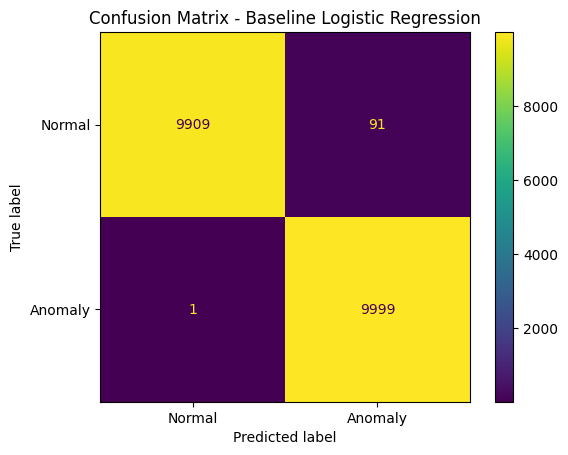

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_class_test, baseline_clf_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Anomaly"]
)

plt.figure(figsize=(6, 5))
disp.plot(values_format="d")
plt.title("Confusion Matrix - Baseline Logistic Regression")
plt.grid(False)
plt.show()

# Deep Learning Classifier for Congestion Detection

In [11]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

dl_classifier = Sequential([
    Dense(64, activation="relu", input_shape=(X_class_train.shape[1],)),
    Dropout(0.3),

    Dense(32, activation="relu"),
    Dropout(0.2),

    Dense(1, activation="sigmoid")
])

dl_classifier.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

dl_classifier.summary()

I0000 00:00:1778748247.793450   18092 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/home/biraj01/.local/lib/python3.10/site-packages/keras/src/layers/core/dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,689 (10.50 KB)

 Trainable params: 2,689 (10.50 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
history_dl_classifier = dl_classifier.fit(
    X_class_train,
    y_class_train,
    validation_split=0.2,
    epochs=20,
    batch_size=32,
    verbose=1
)

Epoch 1/20
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9817 - loss: 0.0548 - val_accuracy: 0.9982 - val_loss: 0.0070
Epoch 2/20
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9980 - loss: 0.0068 - val_accuracy: 0.9969 - val_loss: 0.0072
Epoch 3/20
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9986 - loss: 0.0049 - val_accuracy: 0.9984 - val_loss: 0.0039
Epoch 4/20
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9989 - loss: 0.0040 - val_accuracy: 0.9984 - val_loss: 0.0042
Epoch 5/20
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9991 - loss: 0.0033 - val_accuracy: 0.9992 - val_loss: 0.0021
Epoch 6/20
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9991 - loss: 0.0032 - val_accuracy: 0.9995 - val_loss: 0.0017
Epoch 7/20
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9990 - loss: 0.0030 - val_accuracy: 0.9994 - val_loss: 0.0023
Epoch 8/20
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9991 - loss: 0.0029 - 

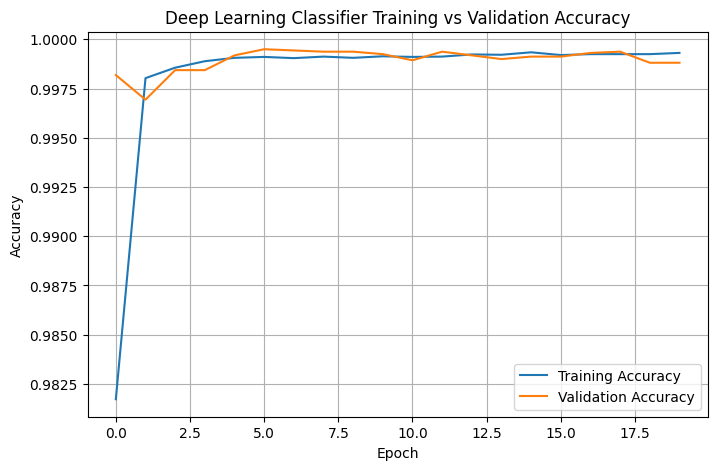

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(history_dl_classifier.history["accuracy"], label="Training Accuracy")
plt.plot(history_dl_classifier.history["val_accuracy"], label="Validation Accuracy")

plt.title("Deep Learning Classifier Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

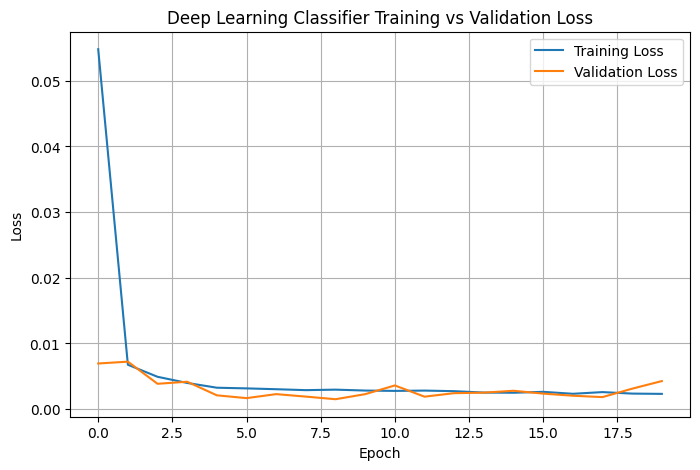

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(history_dl_classifier.history["loss"], label="Training Loss")
plt.plot(history_dl_classifier.history["val_loss"], label="Validation Loss")

plt.title("Deep Learning Classifier Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [15]:
dl_pred_prob = dl_classifier.predict(X_class_test)

dl_pred = (dl_pred_prob > 0.5).astype(int).reshape(-1)

dl_accuracy = accuracy_score(y_class_test, dl_pred)
dl_precision = precision_score(y_class_test, dl_pred)
dl_recall = recall_score(y_class_test, dl_pred)
dl_f1 = f1_score(y_class_test, dl_pred)

print("Deep Learning Classification Results")
print("Accuracy:", dl_accuracy)
print("Precision:", dl_precision)
print("Recall:", dl_recall)
print("F1-score:", dl_f1)

print("\nConfusion Matrix:")
print(confusion_matrix(y_class_test, dl_pred))

print("\nClassification Report:")
print(classification_report(y_class_test, dl_pred))

625/625 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Deep Learning Classification Results
Accuracy: 0.99885
Precision: 0.9977052778609199
Recall: 1.0
F1-score: 0.998851320980872

Confusion Matrix:
[[ 9977    23]
 [    0 10000]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     10000
           1       1.00      1.00      1.00     10000

    accuracy                           1.00     20000
   macro avg       1.00      1.00      1.00     20000
weighted avg       1.00      1.00      1.00     20000



<Figure size 600x500 with 0 Axes>

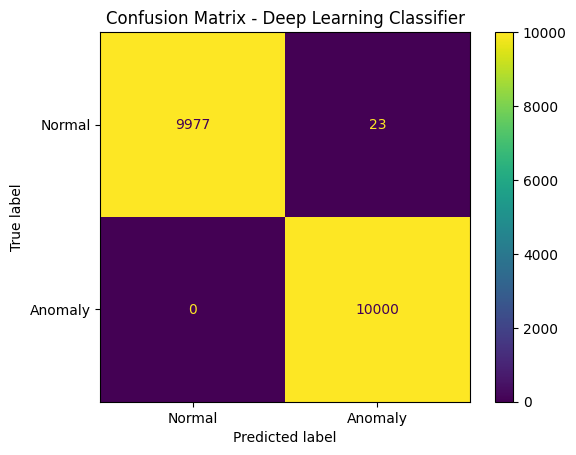

In [16]:
cm_dl = confusion_matrix(y_class_test, dl_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dl,
    display_labels=["Normal", "Anomaly"]
)

plt.figure(figsize=(6, 5))
disp.plot(values_format="d")
plt.title("Confusion Matrix - Deep Learning Classifier")
plt.grid(False)
plt.show()

# CNN-BiLSTM Classifier for Congestion and Anomaly Detection
The previous classifier used each traffic record independently. In this section, a CNN-BiLSTM classifier is used so the model can learn traffic patterns across a sequence of time steps. The target variable is `congestion_anomaly`, where 0 represents normal traffic and 1 represents congestion/anomaly.

In [17]:
class_sequence_data = np.array([
    [
        float(row["hour"]),
        float(row["count_point_id"]),
        float(row["pedal_cycles"]),
        float(row["two_wheeled_motor_vehicles"]),
        float(row["cars_and_taxis"]),
        float(row["buses_and_coaches"]),
        float(row["LGVs"]),
        float(row["all_HGVs"]),
        int(row["congestion_anomaly"])
    ]
    for row in classification_rows
])

X_class_features = class_sequence_data[:, :-1]
y_class_labels = class_sequence_data[:, -1].astype(int)

class_scaler_seq = MinMaxScaler()
X_class_scaled_full = class_scaler_seq.fit_transform(X_class_features)

print("X_class_scaled_full:", X_class_scaled_full.shape)
print("y_class_labels:", y_class_labels.shape)
print("Class counts:", np.unique(y_class_labels, return_counts=True))

X_class_scaled_full: (100000, 8)
y_class_labels: (100000,)
Class counts: (array([0, 1]), array([50000, 50000]))


In [18]:
def create_classification_sequences(features, labels, window_size=8):
    X_seq = []
    y_seq = []

    for i in range(len(features) - window_size):
        X_seq.append(features[i:i + window_size])
        y_seq.append(labels[i + window_size])

    return np.array(X_seq), np.array(y_seq)


window_size = 8

X_class_seq, y_class_seq = create_classification_sequences(
    X_class_scaled_full,
    y_class_labels,
    window_size
)

print("X_class_seq shape:", X_class_seq.shape)
print("y_class_seq shape:", y_class_seq.shape)
print("Sequence class counts:", np.unique(y_class_seq, return_counts=True))

X_class_seq shape: (99992, 8, 8)
y_class_seq shape: (99992,)
Sequence class counts: (array([0, 1]), array([49992, 50000]))


In [19]:
from sklearn.model_selection import train_test_split

X_seq_train, X_seq_test, y_seq_train, y_seq_test = train_test_split(
    X_class_seq,
    y_class_seq,
    test_size=0.2,
    random_state=42,
    stratify=y_class_seq
)

print("X_seq_train:", X_seq_train.shape)
print("X_seq_test:", X_seq_test.shape)
print("y_seq_train:", y_seq_train.shape)
print("y_seq_test:", y_seq_test.shape)

print("Train class counts:", np.unique(y_seq_train, return_counts=True))
print("Test class counts:", np.unique(y_seq_test, return_counts=True))

X_seq_train: (79993, 8, 8)
X_seq_test: (19999, 8, 8)
y_seq_train: (79993,)
y_seq_test: (19999,)
Train class counts: (array([0, 1]), array([39993, 40000]))
Test class counts: (array([0, 1]), array([ 9999, 10000]))


### CNN-BiLSTM Classification Model Architecture

In [22]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Bidirectional, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

cnn_bilstm_classifier = Sequential([
    Conv1D(
        filters=32,
        kernel_size=3,
        activation="relu",
        padding="same",
        input_shape=(X_seq_train.shape[1], X_seq_train.shape[2])
    ),

    MaxPooling1D(pool_size=2),

    Bidirectional(LSTM(32)),

    Dropout(0.2),

    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")
])

cnn_bilstm_classifier.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stop_cls = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

cnn_bilstm_classifier.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_2 (Conv1D)               │ (None, 8, 32)          │           800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 4, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 64)             │        16,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,497 (72.25 KB)

 Trainable params: 18,497 (72.25 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
history_cnn_bilstm_classifier = cnn_bilstm_classifier.fit(
    X_seq_train,
    y_seq_train,
    validation_split=0.2,
    epochs=8,
    batch_size=128,
    callbacks=[early_stop_cls],
    verbose=1
)

W0000 00:00:1778749215.127923   18092 cpu_allocator_impl.cc:82] Allocation of 16382464 exceeds 10% of free system memory.


Epoch 1/8
 13/500 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - accuracy: 0.6366 - loss: 0.6804

W0000 00:00:1778749220.138080   18752 cpu_allocator_impl.cc:82] Allocation of 4967424 exceeds 10% of free system memory.
W0000 00:00:1778749220.169925   18764 cpu_allocator_impl.cc:82] Allocation of 4967424 exceeds 10% of free system memory.
W0000 00:00:1778749220.190720   18759 cpu_allocator_impl.cc:82] Allocation of 4967424 exceeds 10% of free system memory.


500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.9880 - loss: 0.0473 - val_accuracy: 0.9999 - val_loss: 7.7294e-04
Epoch 2/8
500/500 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9997 - loss: 0.0012 - val_accuracy: 0.9999 - val_loss: 2.8497e-04
Epoch 3/8
500/500 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9998 - loss: 7.6511e-04 - val_accuracy: 0.9999 - val_loss: 4.9820e-04
Epoch 4/8
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9998 - loss: 8.9157e-04 - val_accuracy: 0.9999 - val_loss: 2.7765e-04
Epoch 5/8
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9998 - loss: 7.4704e-04 - val_accuracy: 0.9999 - val_loss: 1.3251e-04
Epoch 6/8
500/500 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9999 - loss: 6.0119e-04 - val_accuracy: 0.9999 - val_loss: 1.2521e-04
Epoch 7/8
500/500 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9999 - loss: 5.1160e-04 - val_accuracy: 0.9998 - val_loss: 4.2022e-04
Epoch 8/8
500/500 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9999 

In [24]:
cnn_bilstm_cls_prob = cnn_bilstm_classifier.predict(X_seq_test)

cnn_bilstm_cls_pred = (cnn_bilstm_cls_prob > 0.5).astype(int).reshape(-1)

cnn_bilstm_cls_accuracy = accuracy_score(y_seq_test, cnn_bilstm_cls_pred)
cnn_bilstm_cls_precision = precision_score(y_seq_test, cnn_bilstm_cls_pred)
cnn_bilstm_cls_recall = recall_score(y_seq_test, cnn_bilstm_cls_pred)
cnn_bilstm_cls_f1 = f1_score(y_seq_test, cnn_bilstm_cls_pred)

print("CNN-BiLSTM Classification Results")
print("Accuracy:", cnn_bilstm_cls_accuracy)
print("Precision:", cnn_bilstm_cls_precision)
print("Recall:", cnn_bilstm_cls_recall)
print("F1-score:", cnn_bilstm_cls_f1)

print("\nConfusion Matrix:")
print(confusion_matrix(y_seq_test, cnn_bilstm_cls_pred))

print("\nClassification Report:")
print(classification_report(y_seq_test, cnn_bilstm_cls_pred))

625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step
CNN-BiLSTM Classification Results
Accuracy: 0.99989999499975
Precision: 1.0
Recall: 0.9998
F1-score: 0.9998999899989999

Confusion Matrix:
[[9999    0]
 [   2 9998]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      9999
           1       1.00      1.00      1.00     10000

    accuracy                           1.00     19999
   macro avg       1.00      1.00      1.00     19999
weighted avg       1.00      1.00      1.00     19999



<Figure size 600x500 with 0 Axes>

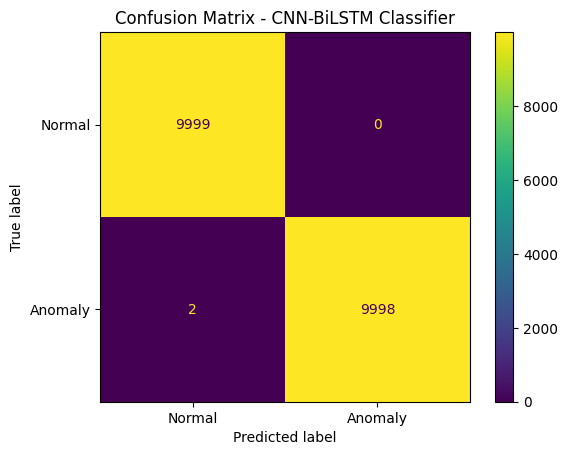

In [25]:
cm_cnn_bilstm = confusion_matrix(y_seq_test, cnn_bilstm_cls_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_cnn_bilstm,
    display_labels=["Normal", "Anomaly"]
)

plt.figure(figsize=(6, 5))
disp.plot(values_format="d")
plt.title("Confusion Matrix - CNN-BiLSTM Classifier")
plt.grid(False)
plt.show()

In [27]:
import pandas as pd

ModuleNotFoundError: No module named 'pandas'

In [28]:
classification_results = [
    ["Logistic Regression", baseline_clf_accuracy, baseline_clf_precision, baseline_clf_recall, baseline_clf_f1],
    ["Dense Neural Network", dl_accuracy, dl_precision, dl_recall, dl_f1],
    ["CNN-BiLSTM Classifier", cnn_bilstm_cls_accuracy, cnn_bilstm_cls_precision, cnn_bilstm_cls_recall, cnn_bilstm_cls_f1]
]

print("Model\t\t\tAccuracy\tPrecision\tRecall\t\tF1-score")
print("-" * 85)

for row in classification_results:
    print(f"{row[0]:25s}\t{row[1]:.5f}\t\t{row[2]:.5f}\t\t{row[3]:.5f}\t\t{row[4]:.5f}")

Model			Accuracy	Precision	Recall		F1-score
-------------------------------------------------------------------------------------
Logistic Regression      	0.99540		0.99098		0.99990		0.99542
Dense Neural Network     	0.99885		0.99771		1.00000		0.99885
CNN-BiLSTM Classifier    	0.99990		1.00000		0.99980		0.99990


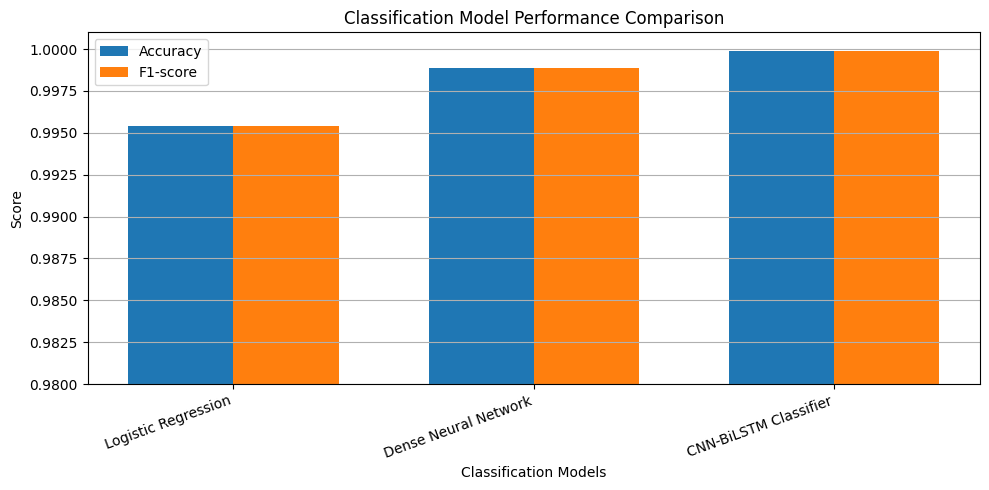

In [29]:
model_names = [row[0] for row in classification_results]
accuracy_scores = [row[1] for row in classification_results]
f1_scores = [row[4] for row in classification_results]

x = np.arange(len(model_names))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(x - width/2, accuracy_scores, width, label="Accuracy")
plt.bar(x + width/2, f1_scores, width, label="F1-score")

plt.xlabel("Classification Models")
plt.ylabel("Score")
plt.title("Classification Model Performance Comparison")
plt.xticks(x, model_names, rotation=20, ha="right")
plt.ylim(0.98, 1.001)
plt.legend()
plt.grid(axis="y")
plt.tight_layout()
plt.show()

The full DfT traffic count dataset was processed using Hadoop HDFS and Apache Spark. After cleaning, the dataset contained 5,113,725 valid records. Exploratory analysis showed that traffic flow varies significantly by hour, region, road type, and vehicle category. Major roads carried much higher traffic volumes than minor roads, and cars/taxis were the dominant vehicle category.

For traffic-flow prediction, three regression models were compared: Linear Regression, LSTM, and CNN-BiLSTM. The LSTM model achieved the best regression performance based on MAE and RMSE.

For congestion/anomaly detection, an IQR-based threshold was used to create the `congestion_anomaly` label. The original dataset contained 457,475 high-traffic anomaly records, representing about 8.95% of the cleaned dataset. A balanced dataset was then created for classification. Logistic Regression, Dense Neural Network, and CNN-BiLSTM classifiers were trained and compared using accuracy, precision, recall, and F1-score. The CNN-BiLSTM classifier achieved very strong classification performance and successfully detected congestion/anomaly cases.

# Context-Based Congestion Classification

To avoid data leakage, this model does not use current vehicle-count features such as `cars_and_taxis`, `LGVs`, `all_HGVs`, or `all_motor_vehicles`. Instead, it predicts congestion/anomaly using time, road, and location-based features such as `year`, `hour`, `region_id`, `local_authority_id`, `count_point_id`, `latitude`, `longitude`, `road_type`, and `road_category`.

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, month, dayofweek
from pyspark.ml.feature import StringIndexer
import numpy as np
import matplotlib.pyplot as plt

spark = SparkSession.builder \
    .appName("Context_Based_Classification") \
    .config("spark.sql.shuffle.partitions", "4") \
    .config("spark.driver.memory", "3g") \
    .getOrCreate()

traffic_labelled = spark.read.parquet(
    "hdfs:///traffic_data/traffic_with_anomaly_label"
)

print("Loaded labelled dataset")
print("Rows:", traffic_labelled.count())

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/05/14 15:36:59 WARN Utils: Your hostname, LAPTOP-N51U7423, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/05/14 15:36:59 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/05/14 15:37:00 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
                                                                                

Loaded labelled dataset


[Stage 1:>                                                        (0 + 16) / 16]

Rows: 5113725


In [2]:
from pyspark.sql.functions import col, month, dayofweek
from pyspark.ml.feature import StringIndexer

context_columns = [
    "year",
    "count_date",
    "hour",
    "region_id",
    "local_authority_id",
    "count_point_id",
    "latitude",
    "longitude",
    "easting",
    "northing",
    "direction_of_travel",
    "road_type",
    "road_category",
    "congestion_anomaly"
]

normal_context = traffic_labelled.filter(
    col("congestion_anomaly") == 0
).select(context_columns).limit(50000)

anomaly_context = traffic_labelled.filter(
    col("congestion_anomaly") == 1
).select(context_columns).limit(50000)

context_data = normal_context.union(anomaly_context)

context_data = context_data.withColumn("month", month(col("count_date")))
context_data = context_data.withColumn("day_of_week", dayofweek(col("count_date")))

print("Context rows:", context_data.count())
context_data.groupBy("congestion_anomaly").count().show()

Context rows: 100000


[Stage 10:================================>                        (9 + 7) / 16]

+------------------+-----+
|congestion_anomaly|count|
+------------------+-----+
|                 0|50000|
|                 1|50000|
+------------------+-----+



In [3]:
categorical_columns = [
    "direction_of_travel",
    "road_type",
    "road_category"
]

context_data_indexed = context_data

for c in categorical_columns:
    indexer = StringIndexer(
        inputCol=c,
        outputCol=c + "_index",
        handleInvalid="keep"
    )
    context_data_indexed = indexer.fit(context_data_indexed).transform(context_data_indexed)

context_data_indexed.show(5, truncate=False)

[Stage 30:========================================================(16 + 0) / 16]

+----+----------+----+---------+------------------+--------------+-----------+-----------+-------+--------+-------------------+---------+-------------+------------------+-----+-----------+-------------------------+---------------+-------------------+
|year|count_date|hour|region_id|local_authority_id|count_point_id|latitude   |longitude  |easting|northing|direction_of_travel|road_type|road_category|congestion_anomaly|month|day_of_week|direction_of_travel_index|road_type_index|road_category_index|
+----+----------+----+---------+------------------+--------------+-----------+-----------+-------+--------+-------------------+---------+-------------+------------------+-----+-----------+-------------------------+---------------+-------------------+
|2004|2004-05-21|10  |1        |1                 |51            |49.91501492|-6.31713812|90200  |10585   |N                  |Major    |PA           |0                 |5    |6          |1.0                      |0.0            |1.0              

In [4]:
context_rows = context_data_indexed.select(
    "year",
    "month",
    "day_of_week",
    "hour",
    "region_id",
    "local_authority_id",
    "count_point_id",
    "latitude",
    "longitude",
    "easting",
    "northing",
    "direction_of_travel_index",
    "road_type_index",
    "road_category_index",
    "congestion_anomaly"
).collect()

print("Rows collected:", len(context_rows))
print(context_rows[0])

Rows collected: 100000
Row(year=2004, month=5, day_of_week=6, hour=10, region_id=1, local_authority_id=1, count_point_id=51, latitude=49.91501492, longitude=-6.31713812, easting=90200, northing=10585, direction_of_travel_index=1.0, road_type_index=0.0, road_category_index=1.0, congestion_anomaly=0)


In [5]:
context_array = np.array([
    [
        float(row["year"]),
        float(row["month"]),
        float(row["day_of_week"]),
        float(row["hour"]),
        float(row["region_id"]),
        float(row["local_authority_id"]),
        float(row["count_point_id"]),
        float(row["latitude"]),
        float(row["longitude"]),
        float(row["easting"]),
        float(row["northing"]),
        float(row["direction_of_travel_index"]),
        float(row["road_type_index"]),
        float(row["road_category_index"]),
        int(row["congestion_anomaly"])
    ]
    for row in context_rows
])

X_context = context_array[:, :-1]
y_context = context_array[:, -1].astype(int)

print("X_context shape:", X_context.shape)
print("y_context shape:", y_context.shape)
print("Class counts:", np.unique(y_context, return_counts=True))

X_context shape: (100000, 14)
y_context shape: (100000,)
Class counts: (array([0, 1]), array([50000, 50000]))


In [6]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

context_scaler = MinMaxScaler()
X_context_scaled = context_scaler.fit_transform(X_context)

X_context_train, X_context_test, y_context_train, y_context_test = train_test_split(
    X_context_scaled,
    y_context,
    test_size=0.2,
    random_state=42,
    stratify=y_context
)

print("Train:", X_context_train.shape)
print("Test:", X_context_test.shape)
print("Train class counts:", np.unique(y_context_train, return_counts=True))
print("Test class counts:", np.unique(y_context_test, return_counts=True))

Train: (80000, 14)
Test: (20000, 14)
Train class counts: (array([0, 1]), array([40000, 40000]))
Test class counts: (array([0, 1]), array([10000, 10000]))


# Baseline Model

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

context_lr = LogisticRegression(max_iter=1000)

context_lr.fit(X_context_train, y_context_train)

context_lr_pred = context_lr.predict(X_context_test)

context_lr_accuracy = accuracy_score(y_context_test, context_lr_pred)
context_lr_precision = precision_score(y_context_test, context_lr_pred)
context_lr_recall = recall_score(y_context_test, context_lr_pred)
context_lr_f1 = f1_score(y_context_test, context_lr_pred)

print("Context-Based Logistic Regression Results")
print("Accuracy:", context_lr_accuracy)
print("Precision:", context_lr_precision)
print("Recall:", context_lr_recall)
print("F1-score:", context_lr_f1)

print("\nConfusion Matrix:")
print(confusion_matrix(y_context_test, context_lr_pred))

print("\nClassification Report:")
print(classification_report(y_context_test, context_lr_pred))

Context-Based Logistic Regression Results
Accuracy: 0.96975
Precision: 0.9700790553387371
Recall: 0.9694
F1-score: 0.9697394087930776

Confusion Matrix:
[[9701  299]
 [ 306 9694]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.97      0.97     10000
           1       0.97      0.97      0.97     10000

    accuracy                           0.97     20000
   macro avg       0.97      0.97      0.97     20000
weighted avg       0.97      0.97      0.97     20000



In [9]:
from sklearn.metrics import ConfusionMatrixDisplay

<Figure size 600x500 with 0 Axes>

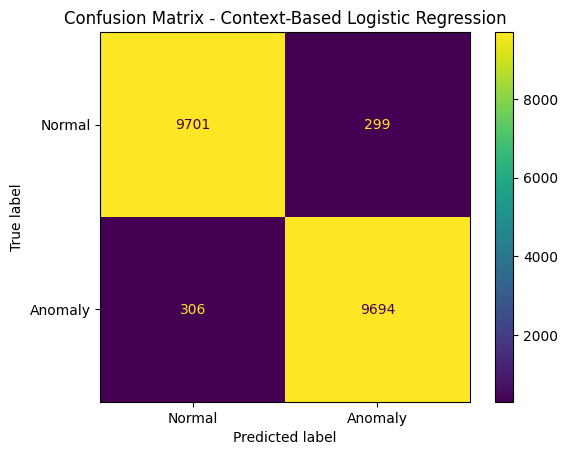

In [10]:
cm_context = confusion_matrix(y_context_test, context_lr_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_context,
    display_labels=["Normal", "Anomaly"]
)

plt.figure(figsize=(6, 5))
disp.plot(values_format="d")
plt.title("Confusion Matrix - Context-Based Logistic Regression")
plt.grid(False)
plt.show()

### Context-Based Dense Neural Network Classifier

In [11]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

context_dense_model = Sequential([
    Dense(64, activation="relu", input_shape=(X_context_train.shape[1],)),
    Dropout(0.3),

    Dense(32, activation="relu"),
    Dropout(0.2),

    Dense(1, activation="sigmoid")
])

context_dense_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

context_dense_model.summary()

I0000 00:00:1778752954.824613   22981 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/home/biraj01/.local/lib/python3.10/site-packages/keras/src/layers/core/dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,073 (12.00 KB)

 Trainable params: 3,073 (12.00 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
history_context_dense = context_dense_model.fit(
    X_context_train,
    y_context_train,
    validation_split=0.2,
    epochs=20,
    batch_size=64,
    verbose=1
)

Epoch 1/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9300 - loss: 0.1762 - val_accuracy: 0.9724 - val_loss: 0.0897
Epoch 2/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9639 - loss: 0.1048 - val_accuracy: 0.9737 - val_loss: 0.0827
Epoch 3/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9684 - loss: 0.0948 - val_accuracy: 0.9742 - val_loss: 0.0777
Epoch 4/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9700 - loss: 0.0884 - val_accuracy: 0.9756 - val_loss: 0.0726
Epoch 5/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9715 - loss: 0.0852 - val_accuracy: 0.9714 - val_loss: 0.0773
Epoch 6/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9727 - loss: 0.0804 - val_accuracy: 0.9768 - val_loss: 0.0663
Epoch 7/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9732 - loss: 0.0779 - val_accuracy: 0.9781 - val_loss: 0.0643
Epoch 8/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9739 - loss: 0.0748 - 

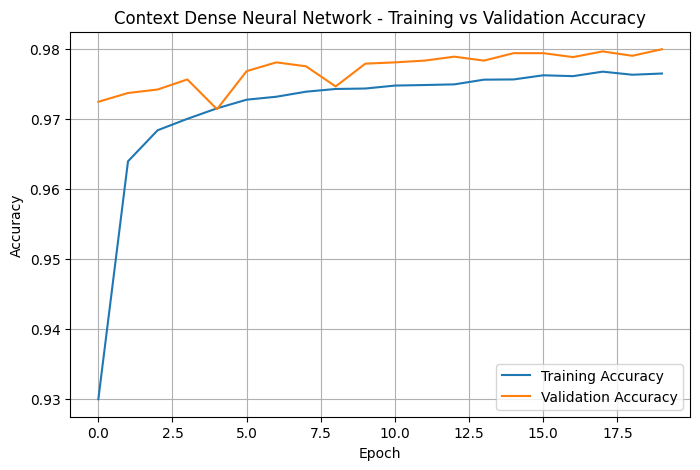

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(history_context_dense.history["accuracy"], label="Training Accuracy")
plt.plot(history_context_dense.history["val_accuracy"], label="Validation Accuracy")

plt.title("Context Dense Neural Network - Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

<Figure size 600x500 with 0 Axes>

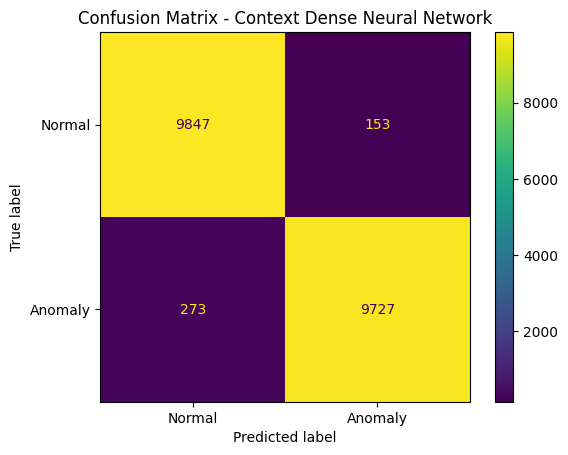

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay

cm_context_dense = confusion_matrix(y_context_test, context_dense_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_context_dense,
    display_labels=["Normal", "Anomaly"]
)

plt.figure(figsize=(6, 5))
disp.plot(values_format="d")
plt.title("Confusion Matrix - Context Dense Neural Network")
plt.grid(False)
plt.show()

In [13]:
context_dense_prob = context_dense_model.predict(X_context_test)
context_dense_pred = (context_dense_prob > 0.5).astype(int).reshape(-1)

context_dense_accuracy = accuracy_score(y_context_test, context_dense_pred)
context_dense_precision = precision_score(y_context_test, context_dense_pred)
context_dense_recall = recall_score(y_context_test, context_dense_pred)
context_dense_f1 = f1_score(y_context_test, context_dense_pred)

print("Context Dense Neural Network Results")
print("Accuracy:", context_dense_accuracy)
print("Precision:", context_dense_precision)
print("Recall:", context_dense_recall)
print("F1-score:", context_dense_f1)

print("\nConfusion Matrix:")
print(confusion_matrix(y_context_test, context_dense_pred))

print("\nClassification Report:")
print(classification_report(y_context_test, context_dense_pred))

625/625 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Context Dense Neural Network Results
Accuracy: 0.9787
Precision: 0.9845141700404858
Recall: 0.9727
F1-score: 0.9785714285714285

Confusion Matrix:
[[9847  153]
 [ 273 9727]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.98      0.98     10000
           1       0.98      0.97      0.98     10000

    accuracy                           0.98     20000
   macro avg       0.98      0.98      0.98     20000
weighted avg       0.98      0.98      0.98     20000



### Context-Based CNN-BiLSTM Classifier

In [17]:
def create_context_sequences(features, labels, window_size=8):
    X_seq = []
    y_seq = []

    for i in range(len(features) - window_size):
        X_seq.append(features[i:i + window_size])
        y_seq.append(labels[i + window_size])

    return np.array(X_seq), np.array(y_seq)


window_size = 8

X_context_seq, y_context_seq = create_context_sequences(
    X_context_scaled,
    y_context,
    window_size
)

print("X_context_seq shape:", X_context_seq.shape)
print("y_context_seq shape:", y_context_seq.shape)
print("Class counts:", np.unique(y_context_seq, return_counts=True))

X_context_seq shape: (99992, 8, 14)
y_context_seq shape: (99992,)
Class counts: (array([0, 1]), array([49992, 50000]))


In [18]:
from sklearn.model_selection import train_test_split

X_context_seq_train, X_context_seq_test, y_context_seq_train, y_context_seq_test = train_test_split(
    X_context_seq,
    y_context_seq,
    test_size=0.2,
    random_state=42,
    stratify=y_context_seq
)

print("X_context_seq_train:", X_context_seq_train.shape)
print("X_context_seq_test:", X_context_seq_test.shape)
print("y_context_seq_train:", y_context_seq_train.shape)
print("y_context_seq_test:", y_context_seq_test.shape)

print("Train class counts:", np.unique(y_context_seq_train, return_counts=True))
print("Test class counts:", np.unique(y_context_seq_test, return_counts=True))

X_context_seq_train: (79993, 8, 14)
X_context_seq_test: (19999, 8, 14)
y_context_seq_train: (79993,)
y_context_seq_test: (19999,)
Train class counts: (array([0, 1]), array([39993, 40000]))
Test class counts: (array([0, 1]), array([ 9999, 10000]))


In [19]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Bidirectional, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

context_cnn_bilstm = Sequential([
    Conv1D(
        filters=32,
        kernel_size=3,
        activation="relu",
        padding="same",
        input_shape=(X_context_seq_train.shape[1], X_context_seq_train.shape[2])
    ),

    MaxPooling1D(pool_size=2),

    Bidirectional(LSTM(32)),

    Dropout(0.2),

    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")
])

context_cnn_bilstm.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stop_context = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

context_cnn_bilstm.summary()

/home/biraj01/.local/lib/python3.10/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 8, 32)          │         1,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 4, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 64)             │        16,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,073 (74.50 KB)

 Trainable params: 19,073 (74.50 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
history_context_cnn_bilstm = context_cnn_bilstm.fit(
    X_context_seq_train,
    y_context_seq_train,
    validation_split=0.2,
    epochs=8,
    batch_size=128,
    callbacks=[early_stop_context],
    verbose=1
)

Epoch 1/8
500/500 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.9706 - loss: 0.0917 - val_accuracy: 0.9836 - val_loss: 0.0444
Epoch 2/8
500/500 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9858 - loss: 0.0432 - val_accuracy: 0.9897 - val_loss: 0.0310
Epoch 3/8
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9869 - loss: 0.0384 - val_accuracy: 0.9912 - val_loss: 0.0271
Epoch 4/8
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9885 - loss: 0.0326 - val_accuracy: 0.9909 - val_loss: 0.0257
Epoch 5/8
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9879 - loss: 0.0327 - val_accuracy: 0.9922 - val_loss: 0.0238
Epoch 6/8
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.9895 - loss: 0.0293 - val_accuracy: 0.9911 - val_loss: 0.0244
Epoch 7/8
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9904 - loss: 0.0266 - val_accuracy: 0.9931 - val_loss: 0.0199
Epoch 8/8
500/500 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9906 - loss: 0.0257 - val_accuracy: 0.99

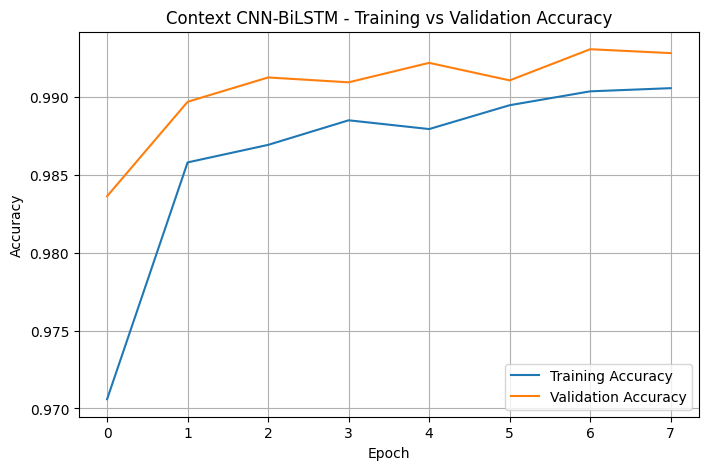

In [21]:
plt.figure(figsize=(8, 5))

plt.plot(history_context_cnn_bilstm.history["accuracy"], label="Training Accuracy")
plt.plot(history_context_cnn_bilstm.history["val_accuracy"], label="Validation Accuracy")

plt.title("Context CNN-BiLSTM - Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [23]:
context_cnn_bilstm_prob = context_cnn_bilstm.predict(X_context_seq_test)

context_cnn_bilstm_pred = (context_cnn_bilstm_prob > 0.5).astype(int).reshape(-1)

context_cnn_bilstm_accuracy = accuracy_score(y_context_seq_test, context_cnn_bilstm_pred)
context_cnn_bilstm_precision = precision_score(y_context_seq_test, context_cnn_bilstm_pred)
context_cnn_bilstm_recall = recall_score(y_context_seq_test, context_cnn_bilstm_pred)
context_cnn_bilstm_f1 = f1_score(y_context_seq_test, context_cnn_bilstm_pred)

print("Context CNN-BiLSTM Results")
print("Accuracy:", context_cnn_bilstm_accuracy)
print("Precision:", context_cnn_bilstm_precision)
print("Recall:", context_cnn_bilstm_recall)
print("F1-score:", context_cnn_bilstm_f1)

print("\nConfusion Matrix:")
print(confusion_matrix(y_context_seq_test, context_cnn_bilstm_pred))

print("\nClassification Report:")
print(classification_report(y_context_seq_test, context_cnn_bilstm_pred))

625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step
Context CNN-BiLSTM Results
Accuracy: 0.9910495524776238
Precision: 0.9899231766936047
Recall: 0.9922
F1-score: 0.9910602806772212

Confusion Matrix:
[[9898  101]
 [  78 9922]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      9999
           1       0.99      0.99      0.99     10000

    accuracy                           0.99     19999
   macro avg       0.99      0.99      0.99     19999
weighted avg       0.99      0.99      0.99     19999



<Figure size 600x500 with 0 Axes>

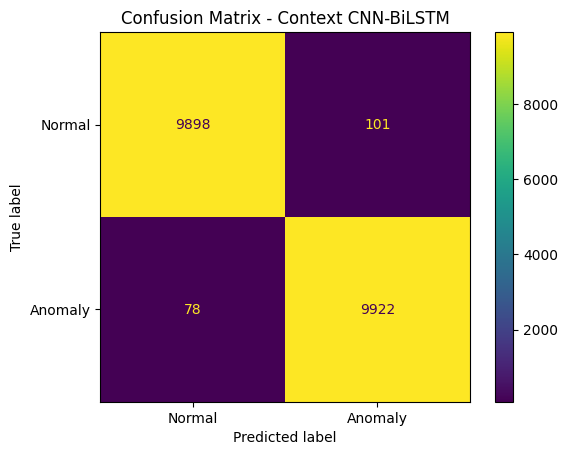

In [24]:
from sklearn.metrics import ConfusionMatrixDisplay

cm_context_cnn_bilstm = confusion_matrix(
    y_context_seq_test,
    context_cnn_bilstm_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_context_cnn_bilstm,
    display_labels=["Normal", "Anomaly"]
)

plt.figure(figsize=(6, 5))
disp.plot(values_format="d")
plt.title("Confusion Matrix - Context CNN-BiLSTM")
plt.grid(False)
plt.show()

In [25]:
context_classification_results = [
    ["Context Logistic Regression", context_lr_accuracy, context_lr_precision, context_lr_recall, context_lr_f1],
    ["Context Dense Neural Network", context_dense_accuracy, context_dense_precision, context_dense_recall, context_dense_f1],
    ["Context CNN-BiLSTM", context_cnn_bilstm_accuracy, context_cnn_bilstm_precision, context_cnn_bilstm_recall, context_cnn_bilstm_f1]
]

print("Context-Based Classification Model Comparison")
print("-" * 105)
print(f"{'Model':32s} {'Accuracy':12s} {'Precision':12s} {'Recall':12s} {'F1-score':12s}")
print("-" * 105)

for row in context_classification_results:
    print(f"{row[0]:32s} {row[1]:<12.5f} {row[2]:<12.5f} {row[3]:<12.5f} {row[4]:<12.5f}")

Context-Based Classification Model Comparison
---------------------------------------------------------------------------------------------------------
Model                            Accuracy     Precision    Recall       F1-score    
---------------------------------------------------------------------------------------------------------
Context Logistic Regression      0.96975      0.97008      0.96940      0.96974     
Context Dense Neural Network     0.97870      0.98451      0.97270      0.97857     
Context CNN-BiLSTM               0.99105      0.98992      0.99220      0.99106     


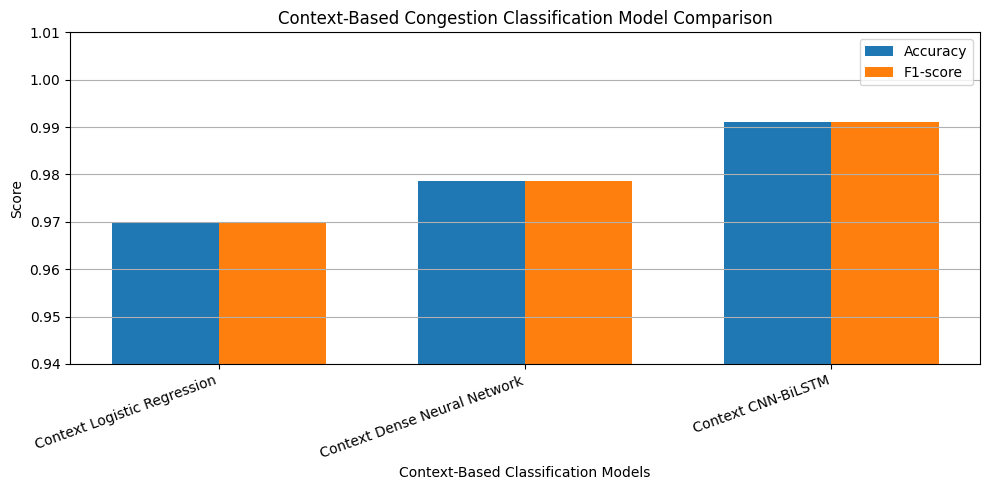

In [26]:
models_cls = [row[0] for row in context_classification_results]
accuracy_values = [row[1] for row in context_classification_results]
f1_values = [row[4] for row in context_classification_results]

x = np.arange(len(models_cls))
width = 0.35

plt.figure(figsize=(10, 5))
plt.bar(x - width/2, accuracy_values, width, label="Accuracy")
plt.bar(x + width/2, f1_values, width, label="F1-score")

plt.xlabel("Context-Based Classification Models")
plt.ylabel("Score")
plt.title("Context-Based Congestion Classification Model Comparison")
plt.xticks(x, models_cls, rotation=20, ha="right")
plt.ylim(0.94, 1.01)
plt.legend()
plt.grid(axis="y")
plt.tight_layout()
plt.show()

For traffic-flow prediction, the LSTM model achieved the best regression performance based on the lowest MAE and RMSE. The CNN-BiLSTM regression model did not outperform the standalone LSTM, which may be due to the short sequence length and the structure of the DfT traffic count dataset.

For congestion/anomaly detection using context-based features, the CNN-BiLSTM classifier achieved the best classification performance. It outperformed Logistic Regression and the Dense Neural Network in accuracy, recall, and F1-score, showing that sequence-based road, time, and location patterns are useful for detecting congestion risk.